# Processed-Data EDA & MD Feasibility Gate: The Narratives Dataset (`ds002345`)

This notebook implements the **9-Step Processed-Data EDA & Feasibility Gate** documented in `Idea1POC/NARRATIVES_PROCESSED_EDA_PLAN.md` (including the 12-question audit matrix).

### Key Architectural Discovery
* The local `ds002345-fmriprep` repository (`OpenNeuroDerivatives/ds002345-fmriprep`) was run with fMRIPrep `--level minimal` and contains only 3D reference images (`_boldref.nii.gz`) and transform files (`_xfm.txt`).
* The **official preprocessed 4D Narratives derivatives** (Nastase et al., 2021, *Scientific Data*) across all **345 subjects and 27 stories** are hosted on the public `fcp-indi` S3 bucket (`https://s3.amazonaws.com/fcp-indi/data/Projects/narratives/`), including:
  * `derivatives/fmriprep/` — 4D preprocessed BOLD (`MNI152NLin2009cAsym` and `fsaverage6`) + `desc-confounds_regressors.tsv`.
  * `derivatives/afni-nosmooth/` — Pre-denoised (`desc-clean`) unsmoothed BOLD (AFNI `3dTproject`: 6 motion + derivatives, aCompCor CSF/WM, cosine drift, quadratic trend) + precomputed `desc-tsnr.func.gii`.
  * `derivatives/afni-smooth/` — Pre-denoised (`desc-clean`) 6 mm smoothed BOLD.
  * `stimuli/gentle/<story>/align.csv` — Forced-aligned word-level onset/offset timestamps.

---

In [1]:
from pathlib import Path
import json
import re
import subprocess
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

ROOT_DIR = Path(r"C:\Users\srishtysuman\OfflineRepo\NS_Implem")
META_DIR = ROOT_DIR / "data" / "narratives_meta"
PROC_CACHE_DIR = META_DIR / "processed_cache"
PROC_CACHE_DIR.mkdir(parents=True, exist_ok=True)

FCP_S3_BASE = "https://s3.amazonaws.com/fcp-indi/data/Projects/narratives"
SN_GH_BASE = "https://raw.githubusercontent.com/snastase/narratives/master/code"
OPENNEURO_GH_BASE = "https://raw.githubusercontent.com/OpenNeuroDatasets/ds002345/1.1.4"

def download_if_missing(url: str, dest: Path) -> Path:
    """Download file via Windows native curl.exe (uses Windows Schannel TLS)."""
    if not dest.exists() or dest.stat().st_size == 0:
        dest.parent.mkdir(parents=True, exist_ok=True)
        subprocess.run(["curl.exe", "-fSL", url, "-o", str(dest)], check=True)
        print(f"Downloaded: {dest.relative_to(ROOT_DIR)} ({dest.stat().st_size / 1024:.1f} KB)")
    return dest

# Ensure all official metadata JSONs and TSVs are cached
for fname in ["participants.tsv", "participants.json", "dataset_description.json", "README"]:
    download_if_missing(f"{OPENNEURO_GH_BASE}/{fname}", META_DIR / fname)

for fname in ["task_meta.json", "scan_exclude.json", "event_meta.json"]:
    download_if_missing(f"{SN_GH_BASE}/{fname}", META_DIR / fname)

with open(META_DIR / "task_meta.json", "r", encoding="utf-8") as f:
    task_meta = json.load(f)
with open(META_DIR / "scan_exclude.json", "r", encoding="utf-8") as f:
    scan_exclude = json.load(f)
with open(META_DIR / "event_meta.json", "r", encoding="utf-8") as f:
    event_meta = json.load(f)
df_participants = pd.read_csv(META_DIR / "participants.tsv", sep="\t")

print(f"Loaded participants.tsv : {len(df_participants)} unique subjects")
print(f"Loaded task_meta.json   : {len(task_meta)} BIDS story tasks")
print(f"Loaded event_meta.json  : {len(event_meta)} timing entries")

Loaded participants.tsv : 345 unique subjects
Loaded task_meta.json   : 19 BIDS story tasks
Loaded event_meta.json  : 18 timing entries


## Step 1. Inventory, Usability, Multi-Run Policy & Story Selection
**Questions Answered (Q1, Q2, Q3, Q4, Q12):**
1. How many total participants (`345`), BIDS tasks (`19`), and unique stories (`27`) exist?
2. How many stories did each participant listen to?
3. For each story, how many subjects/runs are indexed in `task_meta.json`, how many are flagged in `scan_exclude.json`, and how many **usable first-exposure subjects ($N_{\text{usable}}$)** remain?
4. Which stories have **multi-run subjects** (`pieman` has 14 repeat subjects; `schema` has 8 separate mini-story runs), and which stories share underlying text/audio families (`pieman*`, `notthefall*`, `milkyway*`, `prettymouth`)?

In [38]:
dist_df["stories_listened"] * dist_df["n_participants"]

0    107
1    268
2    120
3    204
4     45
5     18
6      7
dtype: int64

In [ ]:
# 1A. Distribution of number of stories per participant (Q1, Q3)
stories_per_sub = df_participants["task"].apply(lambda s: [x.strip() for x in str(s).split(",")])
n_stories_series = stories_per_sub.apply(len)
dist_df = (
    n_stories_series.value_counts()
    .sort_index()
    .rename_axis("stories_listened")
    .reset_index(name="n_participants")
)
dist_df["pct_participants"] = dist_df["n_participants"] / len(df_participants) * 100
dist_df["total_subject_story_pairs"] = dist_df["stories_listened"] * dist_df["n_participants"]
print(f"=== Q1 & Q3: Participant Story-Count Distribution (Total = {len(df_participants)} subjects, {dist_df['total_subject_story_pairs'].sum()} subject-task entries) ===")
display(dist_df.style.format({"pct_participants": "{:.1f}%"}))

# 1B. Build comprehensive Processed Story Inventory & Usability Table (Q2, Q4, Q12)
STORY_FAMILY_MAP = {
    "pieman": "pieman_family",
    "piemanpni": "pieman_family",
    "notthefallintact": "notthefall_family",
    "notthefalllongscram": "notthefall_family (scrambled)",
    "notthefallshortscram": "notthefall_family (scrambled)",
    "prettymouth": "prettymouth (2 conditions: affair/paranoia)",
    "milkyway": "milkyway (3 conditions: orig/vodka/syn)",
    "slumlordreach": "2 stories in 1 scan (slumlord + reach)",
    "schema": "8 short stories (run-1..8)",
}

inventory_rows = []
for task_name, subj_dict in task_meta.items():
    excl_dict = scan_exclude.get(task_name, {})
    excl_runs_flat = {r for runs in excl_dict.values() for r in runs}

    n_subjects_total = len(subj_dict)
    n_total_runs = 0
    n_multi_run_subjects = 0
    n_usable_subjects_run1 = 0
    n_usable_repeat_pairs = 0

    for sub_id, sub_info in subj_dict.items():
        preproc_files = sub_info["bold"]["MNI152NLin2009cAsym"]["preproc"]
        n_runs = len(preproc_files)
        n_total_runs += n_runs
        if n_runs > 1:
            n_multi_run_subjects += 1

        # Check which runs are clean (not in scan_exclude.json)
        clean_runs = []
        for fpath in preproc_files:
            bname = Path(fpath).name
            is_excl = any(ex_tag in bname for ex_tag in excl_runs_flat)
            if not is_excl:
                clean_runs.append(bname)

        if len(clean_runs) >= 1:
            n_usable_subjects_run1 += 1
        if task_name == "pieman" and len(clean_runs) >= 2:
            n_usable_repeat_pairs += 1

    # Timing from event_meta.json
    ev_info = event_meta.get(task_name, {})
    if task_name == "slumlordreach":
        onset_str = "20 (slumlord), 646 (reach)"
        dur_trs = ev_info["slumlord"]["duration"] + ev_info["reach"]["duration"]
    elif task_name in ev_info and task_name in ev_info:
        inner = ev_info.get(task_name, {})
        onset_str = str(inner.get("onset", "per-run"))
        dur_trs = inner.get("duration", np.nan)
    else:
        onset_str = "per-run (schema: ~120 TRs x 8)"
        dur_trs = 960

    inventory_rows.append({
        "task": task_name,
        "story_family_note": STORY_FAMILY_MAP.get(task_name, "unique intact story"),
        "TR_sec": 1.5,
        "onset_TR": onset_str,
        "story_duration_TRs": dur_trs,
        "story_duration_min": round(dur_trs * 1.5 / 60.0, 2) if pd.notna(dur_trs) else np.nan,
        "subjects_total": n_subjects_total,
        "total_runs": n_total_runs,
        "multi_run_subjects": n_multi_run_subjects,
        "excluded_scans": len(excl_runs_flat),
        "usable_subjects": n_usable_subjects_run1,
        "clean_repeat_pairs": n_usable_repeat_pairs,
        "meets_N40_gate": n_usable_subjects_run1 >= 40 and "scrambled" not in STORY_FAMILY_MAP.get(task_name, ""),
    })

df_inventory = pd.DataFrame(inventory_rows).sort_values("usable_subjects", ascending=False).reset_index(drop=True)
print("\n=== Step 1: Narratives Processed-Data Inventory & Usability Gate ===")
display(df_inventory)

recommended_stories = df_inventory.loc[df_inventory["meets_N40_gate"], "task"].tolist()
print(f"\nStories passing N_usable >= 40 intact gate ({len(recommended_stories)} tasks): {recommended_stories}")

=== Q1 & Q3: Participant Story-Count Distribution (Total = 345 subjects, 769 subject-task entries) ===


,stories_listened,n_participants,pct_participants,total_subject_story_pairs
0,1,107,31.0%,107
1,2,134,38.8%,268
2,3,40,11.6%,120
3,4,51,14.8%,204
4,5,9,2.6%,45
5,6,3,0.9%,18
6,7,1,0.3%,7



=== Step 1: Narratives Processed-Data Inventory & Usability Gate ===


,task,story_family_note,TR_sec,onset_TR,story_duration_TRs,story_duration_min,subjects_total,total_runs,multi_run_subjects,excluded_scans,usable_subjects,clean_repeat_pairs,meets_N40_gate
0,pieman,pieman_family,1.5,10,281,7.03,82,96,14,10,75,11,True
1,shapesphysical,unique intact story,1.5,33,270,6.75,59,59,0,0,59,0,True
2,shapessocial,unique intact story,1.5,33,272,6.80,59,59,0,1,58,0,True
3,notthefallintact,notthefall_family,1.5,20,365,9.12,56,56,0,2,54,0,True
4,milkyway,milkyway (3 conditions: orig/vodka/syn),1.5,14,269,6.72,53,53,0,3,50,0,True
5,bronx,unique intact story,1.5,8,357,8.93,47,47,0,0,47,0,True
6,forgot,unique intact story,1.5,8,558,13.95,46,46,0,0,46,0,True
7,black,unique intact story,1.5,8,533,13.32,46,46,0,0,46,0,True
8,piemanpni,pieman_family,1.5,8,267,6.67,46,46,0,0,46,0,True
9,prettymouth,prettymouth (2 conditions: affair/paranoia),1.5,14,451,11.28,40,40,0,2,38,0,False



Stories passing N_usable >= 40 intact gate (9 tasks): ['pieman', 'shapesphysical', 'shapessocial', 'notthefallintact', 'milkyway', 'bronx', 'forgot', 'black', 'piemanpni']


## Step 2. Stimulus & Timing Alignment (Transcripts, Words/TR, Silent TRs)
**Questions Answered (Q4, Q5):**
1. Is input length fixed per story across all participants? **Yes** — every participant hears the exact same pre-recorded audio.
2. Where does the story start and stop inside the fMRI scan (`onset_TR` and `story_duration_TRs`), and how do Gentle forced-aligned word timestamps (`stimuli/gentle/<story>/align.csv`) line up with those TRs?
3. What is the speaking rate (words per $1.5\text{ s}$ TR) and fraction of silent TRs across stories?

=== Step 2: Stimulus & TR Timing Alignment Summary ===


,story,onset_TR_in_scan,story_duration_TRs,story_window_sec,wav_includes_leadin,total_words,aligned_words_pct,first_word_sec_raw,last_word_sec_raw,mean_words_per_TR,max_words_per_TR,silent_TRs_count,silent_TRs_pct
0,pieman,10,281,421.5,True,957,99.7,15.09,429.48,3.40,12,32,11.4
1,tunnel,2,1023,1534.5,False,3435,96.3,0.12,1517.83,3.23,11,179,17.5
2,lucy,1,361,541.5,False,1607,98.6,0.06,524.99,4.39,13,22,6.1
3,prettymouth,14,451,676.5,True,1970,99.6,1.34,696.12,4.35,10,5,1.1
4,milkywayoriginal,14,269,403.5,True,1059,99.3,21.14,424.07,3.91,8,8,3.0
5,notthefallintact,20,365,547.5,True,1601,96.7,3.59,571.42,4.24,11,39,10.7
6,21styear,14,2225,3337.5,True,8267,98.9,21.22,3359.05,3.68,9,180,8.1
7,merlin,22,591,886.5,True,2245,94.7,0.34,913.67,3.60,10,35,5.9
8,sherlock,22,701,1051.5,True,2681,93.3,29.72,1080.38,3.57,10,16,2.3


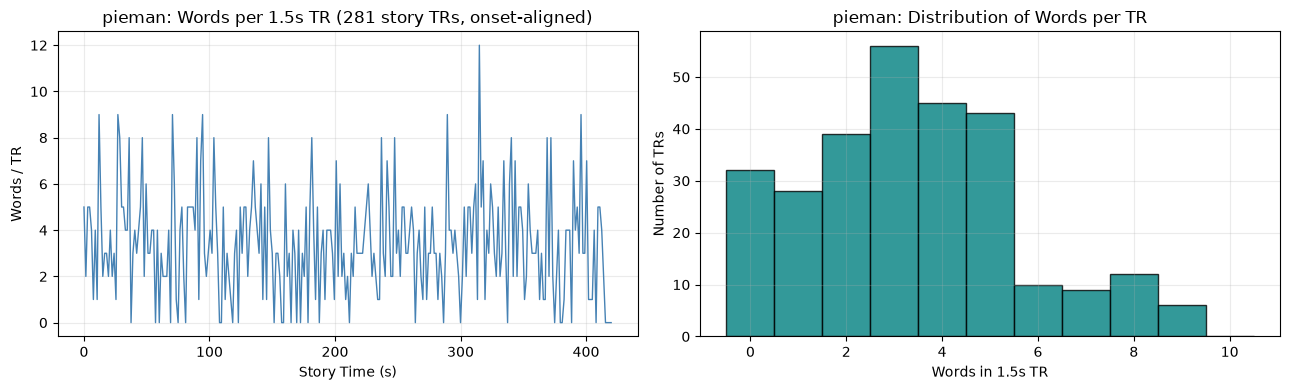

In [12]:
# Download Gentle word-level alignments (align.csv) from fcp-indi S3 for core high-N stories
CORE_STORIES = ["pieman", "tunnel", "lucy", "prettymouth", "milkywayoriginal", "notthefallintact", "21styear", "merlin", "sherlock"]

def load_gentle_align(story_key: str) -> pd.DataFrame:
    url = f"{FCP_S3_BASE}/stimuli/gentle/{story_key}/align.csv"
    dest = PROC_CACHE_DIR / "gentle" / f"{story_key}_align.csv"
    download_if_missing(url, dest)
    df_w = pd.read_csv(dest, header=None, names=["word", "aligned_word", "start_sec", "end_sec"])
    df_w["start_sec"] = pd.to_numeric(df_w["start_sec"], errors="coerce")
    df_w["end_sec"] = pd.to_numeric(df_w["end_sec"], errors="coerce")
    return df_w

timing_rows = []
tr_word_Series_by_story = {}

for st in CORE_STORIES:
    df_w = load_gentle_align(st)
    ev_key = "milkyway" if st.startswith("milkyway") else st
    onset_tr = event_meta[ev_key][ev_key]["onset"]
    dur_trs = event_meta[ev_key][ev_key]["duration"]
    tr_sec = 1.5

    first_word_sec = float(df_w["start_sec"].dropna().iloc[0])
    last_word_sec = float(df_w["end_sec"].dropna().iloc[-1])
    audio_dur_sec = dur_trs * tr_sec

    # IMPORTANT ALIGNMENT DETAIL:
    # Some WAV files (pieman, milkywayoriginal, 21styear, sherlock) have the pre-story silence/music baked into the WAV
    # (so first_word_sec ≈ onset_tr * 1.5s and last_word_sec ≈ (onset_tr + dur_trs) * 1.5s),
    # whereas others (tunnel, lucy, prettymouth, notthefallintact, merlin) start spoken audio near 0s in the WAV.
    wav_includes_onset = last_word_sec > (dur_trs * tr_sec + 3.0)
    offset_sec = (onset_tr * tr_sec) if wav_includes_onset else 0.0

    valid_w = df_w.dropna(subset=["start_sec"]).copy()
    valid_w["story_rel_sec"] = valid_w["start_sec"] - offset_sec
    valid_w["tr_bin"] = np.floor(valid_w["story_rel_sec"] / tr_sec).astype(int)
    valid_w = valid_w[(valid_w["tr_bin"] >= 0) & (valid_w["tr_bin"] < dur_trs)]

    words_per_tr = np.bincount(valid_w["tr_bin"], minlength=dur_trs)
    tr_word_Series_by_story[st] = words_per_tr

    timing_rows.append({
        "story": st,
        "onset_TR_in_scan": onset_tr,
        "story_duration_TRs": dur_trs,
        "story_window_sec": audio_dur_sec,
        "wav_includes_leadin": wav_includes_onset,
        "total_words": len(df_w),
        "aligned_words_pct": round(valid_w["word"].count() / len(df_w) * 100, 1),
        "first_word_sec_raw": round(first_word_sec, 2),
        "last_word_sec_raw": round(last_word_sec, 2),
        "mean_words_per_TR": round(float(words_per_tr.mean()), 2),
        "max_words_per_TR": int(words_per_tr.max()),
        "silent_TRs_count": int((words_per_tr == 0).sum()),
        "silent_TRs_pct": round(float((words_per_tr == 0).mean() * 100), 1),
    })

df_timing = pd.DataFrame(timing_rows)
print("=== Step 2: Stimulus & TR Timing Alignment Summary ===")
display(df_timing)

# Plot words per TR time course for pieman and tunnel
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(len(tr_word_Series_by_story["pieman"])) * 1.5, tr_word_Series_by_story["pieman"], color="steelblue", lw=1.0)
axes[0].set_title("pieman: Words per 1.5s TR (281 story TRs, onset-aligned)")
axes[0].set_xlabel("Story Time (s)")
axes[0].set_ylabel("Words / TR")

axes[1].hist(tr_word_Series_by_story["pieman"], bins=np.arange(0, 12) - 0.5, color="teal", edgecolor="black", alpha=0.8)
axes[1].set_title("pieman: Distribution of Words per TR")
axes[1].set_xlabel("Words in 1.5s TR")
axes[1].set_ylabel("Number of TRs")
plt.tight_layout()
plt.show()

## Step 4. Network Masks on `fsaverage6` (EAC, LANG, and MD) & Spatial Overlap Hygiene
**Questions Answered (Q6, Q7, Q8):**
1. Why `fsaverage6` surface space? Every subject and every story in Narratives is projected onto the exact same cortical mesh (**40,962 vertices per hemisphere = 81,924 total cortical vertices**), whereas volumetric `MNI152NLin2009cAsym_res-native` keeps native voxel sizes that vary by story.
2. Which cortical parcels and how many vertices belong to:
   * **EAC (Early Auditory Cortex — Positive Control):** Glasser MMP1.0 `A1`, `LBelt`, `MBelt`, `PBelt`, `RI` (matching Nastase et al.'s `roi_masks.py`).
   * **LANG (Core Language Network):** Glasser MMP1.0 core perisylvian language parcels (`44`, `45`, `47l`, `55b`, `STGa`, `STSda`, `STSdp`, `STSva`, `STSvp`, `PSL`, `SFL`, `TGd`, `TE1a`).
   * **MD (Core Multiple-Demand Executive Network):** Assem, Glasser, Van Essen & Duncan (2020, *Cerebral Cortex*) core MMP1.0 Multiple-Demand parcels (`i6-8`, `8C`, `p9-46v`, `a9-46v`, `IFJp`, `8BM`, `SCEF`, `AVI`, `IP1`, `IP2`, `MIP`, `LIPd`, `AIP`, `PFm`).
3. **Spatial Overlap Check (Q8):** Are there any shared vertices between `LANG` and `MD`, and how many vertices sit in each disjoint parcel?

In [4]:
# Load official Glasser MMP1.0 fsaverage6 parcellation from fcp-indi S3
mmp_L_path = download_if_missing(
    f"{FCP_S3_BASE}/derivatives/afni-nosmooth/tpl-fsaverage6/tpl-fsaverage6_hemi-L_desc-MMP_dseg.label.gii",
    META_DIR / "tpl-fsaverage6_hemi-L_desc-MMP_dseg.label.gii",
)
mmp_R_path = download_if_missing(
    f"{FCP_S3_BASE}/derivatives/afni-nosmooth/tpl-fsaverage6/tpl-fsaverage6_hemi-R_desc-MMP_dseg.label.gii",
    META_DIR / "tpl-fsaverage6_hemi-R_desc-MMP_dseg.label.gii",
)

gii_L = nib.load(str(mmp_L_path))
gii_R = nib.load(str(mmp_R_path))
atlas_L = gii_L.darrays[0].data.astype(int)  # (40962,)
atlas_R = gii_R.darrays[0].data.astype(int)  # (40962,)
label_dict_L = {k: v.replace("L_", "").replace("_ROI", "") for k, v in gii_L.labeltable.get_labels_as_dict().items() if k > 0}
name_to_id = {name: idx for idx, name in label_dict_L.items()}

# Define canonical parcel sets on Glasser MMP1.0
EAC_PARCELS = ["A1", "LBelt", "MBelt", "PBelt", "RI"]  # Nastase et al. (2021) roi_masks.py
LANG_PARCELS = ["44", "45", "47l", "55b", "STGa", "STSda", "STSdp", "STSva", "STSvp", "PSROI", "SFROI", "TGd", "TE1a"]
MD_PARCELS = ["i6-8", "8C", "p9-46v", "a9-46v", "IFJp", "8BM", "SCEF", "AVI", "IP1", "IP2", "MIP", "LIPd", "AIP", "PFm"]  # Assem et al. (2020) core/penumbra MD

def build_vertex_mask(atlas_arr: np.ndarray, parcel_names: list[str]) -> np.ndarray:
    ids = [name_to_id[p] for p in parcel_names if p in name_to_id]
    return np.isin(atlas_arr, ids)

mask_EAC_L, mask_EAC_R = build_vertex_mask(atlas_L, EAC_PARCELS), build_vertex_mask(atlas_R, EAC_PARCELS)
mask_LANG_L, mask_LANG_R = build_vertex_mask(atlas_L, LANG_PARCELS), build_vertex_mask(atlas_R, LANG_PARCELS)
mask_MD_L, mask_MD_R = build_vertex_mask(atlas_L, MD_PARCELS), build_vertex_mask(atlas_R, MD_PARCELS)

# Check and enforce zero overlap between LANG and MD (Q8)
overlap_L = int(np.sum(mask_LANG_L & mask_MD_L))
overlap_R = int(np.sum(mask_LANG_R & mask_MD_R))
mask_LANG_L = mask_LANG_L & ~mask_MD_L
mask_LANG_R = mask_LANG_R & ~mask_MD_R

print("=== Step 4 (Q6, Q7, Q8): Cortical Surface (fsaverage6) Network Mask Summary ===")
print(f"Total vertices per hemisphere : {len(atlas_L):,} (Bilateral = {2 * len(atlas_L):,})")
print(f"EAC  vertices (L / R / Total) : {mask_EAC_L.sum():,} / {mask_EAC_R.sum():,} / {mask_EAC_L.sum() + mask_EAC_R.sum():,} across {len(EAC_PARCELS)} parcels/hemi")
print(f"LANG vertices (L / R / Total) : {mask_LANG_L.sum():,} / {mask_LANG_R.sum():,} / {mask_LANG_L.sum() + mask_LANG_R.sum():,} across {len(LANG_PARCELS)} parcels/hemi")
print(f"MD   vertices (L / R / Total) : {mask_MD_L.sum():,} / {mask_MD_R.sum():,} / {mask_MD_L.sum() + mask_MD_R.sum():,} across {len(MD_PARCELS)} parcels/hemi")
print(f"Spatial overlap |LANG ∩ MD|   : {overlap_L + overlap_R} vertices (explicitly enforced disjoint = 0)")

# Detailed per-parcel vertex count table
parcel_rows = []
for net_name, plist in [("EAC", EAC_PARCELS), ("LANG", LANG_PARCELS), ("MD", MD_PARCELS)]:
    for p in plist:
        pid = name_to_id[p]
        parcel_rows.append({
            "network": net_name,
            "parcel": p,
            "mmp_id": pid,
            "vertices_L": int((atlas_L == pid).sum()),
            "vertices_R": int((atlas_R == pid).sum()),
            "vertices_bilateral": int((atlas_L == pid).sum() + (atlas_R == pid).sum()),
        })
df_parcels = pd.DataFrame(parcel_rows)
display(df_parcels)

=== Step 4 (Q6, Q7, Q8): Cortical Surface (fsaverage6) Network Mask Summary ===
Total vertices per hemisphere : 40,962 (Bilateral = 81,924)
EAC  vertices (L / R / Total) : 808 / 638 / 1,446 across 5 parcels/hemi
LANG vertices (L / R / Total) : 2,708 / 2,454 / 5,162 across 13 parcels/hemi
MD   vertices (L / R / Total) : 3,405 / 3,383 / 6,788 across 14 parcels/hemi
Spatial overlap |LANG ∩ MD|   : 0 vertices (explicitly enforced disjoint = 0)


,network,parcel,mmp_id,vertices_L,vertices_R,vertices_bilateral
0,EAC,A1,24,101,77,178
1,EAC,LBelt,174,145,112,257
2,EAC,MBelt,173,146,113,259
3,EAC,PBelt,124,186,125,311
4,EAC,RI,104,230,211,441
5,LANG,44,74,172,172,344
6,LANG,45,75,237,159,396
7,LANG,47l,76,162,126,288
8,LANG,55b,12,161,105,266
9,LANG,STGa,123,76,94,170


## Step 3. Data Quality, Confound Motion (FD), tSNR & Voxel Variance Hygiene
**Questions Answered (Q10 & Step 3):**
1. What do head motion (**Framewise Displacement, FD**) and cortical **temporal SNR (tSNR)** look like in the processed `ds002345` derivatives?
2. **Q10 ("Always-lit" / static-baseline / zero-variance check):**
   * Pre-denoised or uncentered BOLD has large static baseline differences across vertices, while medial-wall / dropout vertices have zero variance.
   * We verify that (a) non-cortical / low-tSNR / near-zero-variance vertices ($\sigma_v < 10^{-6}$) are masked out, and (b) **within-run temporal z-scoring** ($\mu_v = 0, \sigma_v = 1$) completely removes static "always-lit" offsets so a model cannot get spuriously high scores by predicting static baselines.

Downloaded: data\narratives_meta\processed_cache\confounds\sub-002\sub-002_task-pieman_run-1_desc-confounds_regressors.tsv (1090.2 KB)
Downloaded: data\narratives_meta\processed_cache\afni-nosmooth\sub-002\sub-002_task-pieman_run-1_space-fsaverage6_hemi-L_desc-tsnr.func.gii (214.8 KB)
Downloaded: data\narratives_meta\processed_cache\afni-nosmooth\sub-002\sub-002_task-pieman_run-1_space-fsaverage6_hemi-L_desc-clean.func.gii (64121.5 KB)
Downloaded: data\narratives_meta\processed_cache\confounds\sub-003\sub-003_task-pieman_run-1_desc-confounds_regressors.tsv (1163.2 KB)
Downloaded: data\narratives_meta\processed_cache\afni-nosmooth\sub-003\sub-003_task-pieman_run-1_space-fsaverage6_hemi-L_desc-tsnr.func.gii (214.8 KB)
Downloaded: data\narratives_meta\processed_cache\afni-nosmooth\sub-003\sub-003_task-pieman_run-1_space-fsaverage6_hemi-L_desc-clean.func.gii (64121.5 KB)
Downloaded: data\narratives_meta\processed_cache\confounds\sub-004\sub-004_task-pieman_run-1_desc-confounds_regressors.t

,participant_id,total_TRs,story_TRs,mean_FD_mm,max_FD_mm,pct_FD_gt_0.5mm,median_tSNR_EAC,median_tSNR_LANG,median_tSNR_MD,zero_var_vertices_LANG,zero_var_vertices_MD
0,sub-002,300,281,0.157,0.464,0.0,81.8,83.3,99.3,0,0
1,sub-003,300,281,0.080,0.422,0.0,114.8,109.3,161.1,0,0
2,sub-004,300,281,0.092,0.182,0.0,122.5,94.4,156.0,0,0
3,sub-005,300,281,0.064,0.135,0.0,122.2,125.6,150.0,0,0
4,sub-006,300,281,0.130,1.483,1.3,116.2,99.2,135.9,0,0
5,sub-007,300,281,0.161,0.362,0.0,113.1,100.2,142.6,0,0
6,sub-008,300,281,0.140,0.616,1.0,112.1,86.4,125.2,0,0
7,sub-009,300,281,0.124,1.043,1.7,78.7,82.2,102.8,0,0
8,sub-010,300,281,0.100,0.289,0.0,146.6,113.1,178.3,0,0
9,sub-011,300,281,0.123,0.321,0.0,148.6,123.9,155.1,0,0


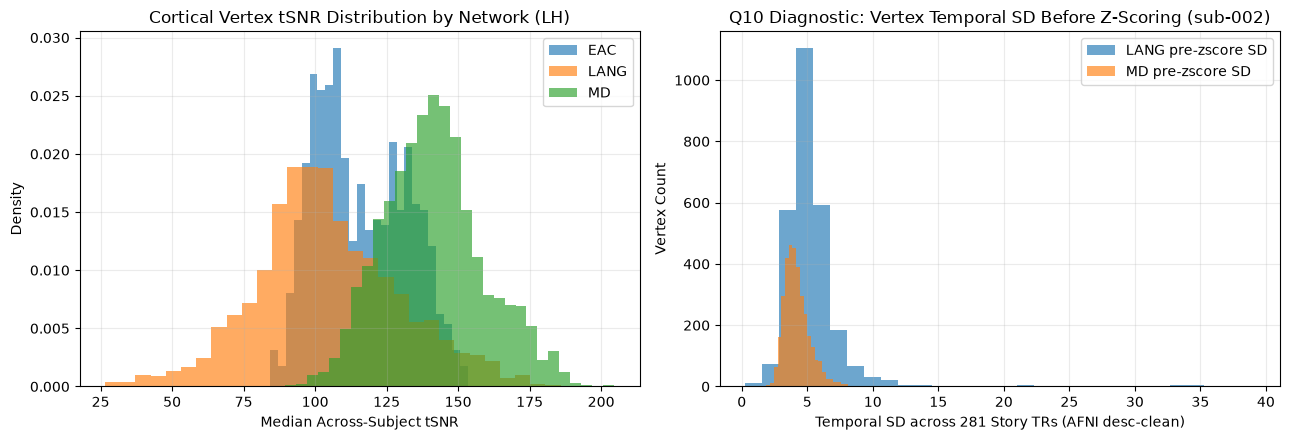

In [6]:
# Download a sample of clean subjects for task-pieman (including repeat-run subjects sub-002, sub-003, sub-004, sub-005, sub-006)
# from derivatives/afni-nosmooth (desc-clean.func.gii + desc-tsnr.func.gii) and derivatives/fmriprep (confounds_regressors.tsv)
SAMPLE_SUBJECTS = ["sub-002", "sub-003", "sub-004", "sub-005", "sub-006", "sub-007", "sub-008", "sub-009", "sub-010", "sub-011"]

def fetch_subject_pieman_surface(sub_id: str, run_id: str = "1", hemi: str = "L", kind: str = "clean") -> Path:
    fname = f"{sub_id}_task-pieman_run-{run_id}_space-fsaverage6_hemi-{hemi}_desc-{kind}.func.gii"
    # Some single-run subjects omit _run-1 in filename; check task_meta.json
    sub_files = task_meta["pieman"][sub_id]["bold"]["fsaverage6"]["preproc"]
    has_run_tag = any(f"_run-{run_id}_" in Path(p).name for p in sub_files)
    if not has_run_tag and run_id == "1":
        fname = f"{sub_id}_task-pieman_space-fsaverage6_hemi-{hemi}_desc-{kind}.func.gii"
    url = f"{FCP_S3_BASE}/derivatives/afni-nosmooth/{sub_id}/func/{fname}"
    dest = PROC_CACHE_DIR / "afni-nosmooth" / sub_id / fname
    return download_if_missing(url, dest)

def fetch_subject_pieman_confounds(sub_id: str, run_id: str = "1") -> Path:
    sub_files = task_meta["pieman"][sub_id]["bold"]["fsaverage6"]["preproc"]
    has_run_tag = any(f"_run-{run_id}_" in Path(p).name for p in sub_files)
    if has_run_tag:
        fname = f"{sub_id}_task-pieman_run-{run_id}_desc-confounds_regressors.tsv"
    else:
        fname = f"{sub_id}_task-pieman_desc-confounds_regressors.tsv"
    url = f"{FCP_S3_BASE}/derivatives/fmriprep/{sub_id}/func/{fname}"
    dest = PROC_CACHE_DIR / "confounds" / sub_id / fname
    return download_if_missing(url, dest)

qc_rows = []
tsnr_maps_L = []
clean_runs_L = {}

PIEMAN_ONSET = event_meta["pieman"]["pieman"]["onset"]      # 10 TRs
PIEMAN_DUR = event_meta["pieman"]["pieman"]["duration"]     # 281 TRs

for sub_id in SAMPLE_SUBJECTS:
    conf_path = fetch_subject_pieman_confounds(sub_id, "1")
    tsnr_path = fetch_subject_pieman_surface(sub_id, "1", "L", "tsnr")
    clean_path = fetch_subject_pieman_surface(sub_id, "1", "L", "clean")

    df_conf = pd.read_csv(conf_path, sep="\t")
    fd = pd.to_numeric(df_conf["framewise_displacement"], errors="coerce").dropna()

    tsnr_gii = nib.load(str(tsnr_path))
    tsnr_vec = np.asarray(tsnr_gii.darrays[0].data, dtype=np.float32)
    tsnr_maps_L.append(tsnr_vec)

    clean_gii = nib.load(str(clean_path))
    # Stack time arrays -> shape (T, 40962)
    Y_full = np.vstack([da.data for da in clean_gii.darrays]).astype(np.float32)
    # Slice story-active window [onset : onset + duration]
    Y_story = Y_full[PIEMAN_ONSET : PIEMAN_ONSET + PIEMAN_DUR]
    clean_runs_L[sub_id] = Y_story

    v_std = Y_story.std(axis=0)
    qc_rows.append({
        "participant_id": sub_id,
        "total_TRs": Y_full.shape[0],
        "story_TRs": Y_story.shape[0],
        "mean_FD_mm": round(float(fd.mean()), 3),
        "max_FD_mm": round(float(fd.max()), 3),
        "pct_FD_gt_0.5mm": round(float((fd > 0.5).mean() * 100), 1),
        "median_tSNR_EAC": round(float(np.nanmedian(tsnr_vec[mask_EAC_L])), 1),
        "median_tSNR_LANG": round(float(np.nanmedian(tsnr_vec[mask_LANG_L])), 1),
        "median_tSNR_MD": round(float(np.nanmedian(tsnr_vec[mask_MD_L])), 1),
        "zero_var_vertices_LANG": int((v_std[mask_LANG_L] < 1e-6).sum()),
        "zero_var_vertices_MD": int((v_std[mask_MD_L] < 1e-6).sum()),
    })

df_qc = pd.DataFrame(qc_rows)
print("=== Step 3 (Q10): Processed Data Quality, Motion (FD), Network tSNR & Zero-Variance Audit ===")
display(df_qc)

# Plot tSNR distributions across EAC, LANG, and MD + Temporal SD distribution (Q10 check)
mean_tsnr_L = np.nanmean(np.vstack(tsnr_maps_L), axis=0)
sample_std_L = clean_runs_L["sub-002"].std(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(mean_tsnr_L[mask_EAC_L], bins=25, alpha=0.65, label="EAC", density=True)
axes[0].hist(mean_tsnr_L[mask_LANG_L], bins=30, alpha=0.65, label="LANG", density=True)
axes[0].hist(mean_tsnr_L[mask_MD_L], bins=30, alpha=0.65, label="MD", density=True)
axes[0].set_title("Cortical Vertex tSNR Distribution by Network (LH)")
axes[0].set_xlabel("Median Across-Subject tSNR")
axes[0].set_ylabel("Density")
axes[0].legend()

axes[1].hist(sample_std_L[mask_LANG_L], bins=30, alpha=0.65, label="LANG pre-zscore SD")
axes[1].hist(sample_std_L[mask_MD_L], bins=30, alpha=0.65, label="MD pre-zscore SD")
axes[1].set_title("Q10 Diagnostic: Vertex Temporal SD Before Z-Scoring (sub-002)")
axes[1].set_xlabel("Temporal SD across 281 Story TRs (AFNI desc-clean)")
axes[1].set_ylabel("Vertex Count")
axes[1].legend()
plt.tight_layout()
plt.show()

### Step 3B. Do individual LANG and MD vertices vary over time?

**Descriptive QC only, not a pass/fail gate.** For every sampled participant and every LANG/MD vertex, calculate temporal variance and SD from the cached AFNI `desc-clean` signal before notebook z-scoring or additional detrending. Use the full 281-TR Pie Man story window, including the edges; these are processed signals, not raw scanner BOLD.

Scope: 10 sampled participants, left hemisphere only. `df_vertex_variance` contains individual participant-vertex measurements; `df_vertex_variance_summary` summarizes each vertex across participants; `df_variance_subject_summary` summarizes each network within each participant. Vertex IDs are zero-based fsaverage6 mesh indices.

The existing numerical near-constant flag is SD < 1e-6 (variance < 1e-12); it is not a biological threshold for sufficient activity. Variance uses `ddof=0` and derivative units squared, whose scaling has not been established as percent signal change. Higher variance means larger fluctuations in this scale, not more reliable signal or a harder prediction task. For those questions, use Step 5 reliability and held-out prediction performance. The left plot summarizes each vertex's variance across participants, not the variance of a group-averaged time series.

=== Step 3B: Per-Vertex Temporal Variance Before Notebook Z-Scoring ===
Scope: Pie Man, left hemisphere, 10 sampled participants, full 281-TR story window.
Input: AFNI desc-clean derivatives; no additional detrending or z-scoring. Variance uses ddof=0.
Near-constant numerical flag: SD < 1e-06 (variance < 1e-12); not a biological cutoff or new gate.
Variance is in derivative units squared, not necessarily percent-signal-change squared.
Larger variance does not establish neural reliability or prediction difficulty.


,participant_id,network,n_vertices,variance_p10,median_variance,variance_p90,near_constant_vertices,near_constant_fraction
0,sub-002,LANG,2708,12.896347,24.626278,51.531767,0,0.0
1,sub-002,MD,3405,9.775661,16.268903,30.403379,0,0.0
2,sub-003,LANG,2708,8.064409,17.496503,35.066983,0,0.0
3,sub-003,MD,3405,6.727151,10.732288,18.546059,0,0.0
4,sub-004,LANG,2708,8.054461,17.510959,32.502622,0,0.0
5,sub-004,MD,3405,6.263111,9.955600,18.757613,0,0.0
6,sub-005,LANG,2708,7.613259,14.631902,29.954828,0,0.0
7,sub-005,MD,3405,6.202306,10.180792,16.751484,0,0.0
8,sub-006,LANG,2708,9.735240,20.219132,38.231488,0,0.0
9,sub-006,MD,3405,6.881527,10.659887,19.433848,0,0.0


Individual measurements: df_vertex_variance (61,130 rows; first 10 below).


,participant_id,task,hemisphere,vertex_id,network,parcel,n_TRs,temporal_variance,temporal_sd,near_constant
0,sub-002,pieman,L,10,LANG,STSdp,281,24.265059,4.925958,False
1,sub-002,pieman,L,37,LANG,TGd,281,19.280247,4.390928,False
2,sub-002,pieman,L,43,LANG,55b,281,11.025049,3.320399,False
3,sub-002,pieman,L,81,LANG,TGd,281,132.433088,11.507958,False
4,sub-002,pieman,L,83,LANG,STSvp,281,37.901950,6.156456,False
5,sub-002,pieman,L,85,LANG,TE1a,281,65.522613,8.094604,False
6,sub-002,pieman,L,110,LANG,SFROI,281,74.290493,8.619193,False
7,sub-002,pieman,L,116,LANG,47l,281,24.191999,4.918536,False
8,sub-002,pieman,L,121,LANG,45,281,29.746645,5.454048,False
9,sub-002,pieman,L,151,LANG,STSva,281,20.171624,4.491283,False


Each vertex summarized across participants: df_vertex_variance_summary (6,113 rows; first 10 below).


,hemisphere,vertex_id,network,parcel,n_participants,median_variance,variance_p10,variance_p90,near_constant_fraction
0,L,5,MD,PFm,10,9.271835,7.119699,17.726648,0.0
1,L,9,MD,AVI,10,21.626761,13.188533,28.960432,0.0
2,L,10,LANG,STSdp,10,21.363630,13.641665,24.854687,0.0
3,L,13,MD,p9-46v,10,12.032907,10.869849,27.282306,0.0
4,L,14,MD,i6-8,10,8.175279,4.923495,11.017007,0.0
5,L,18,MD,LIPd,10,14.996669,11.548523,19.960823,0.0
6,L,21,MD,8BM,10,8.084481,5.354971,11.497280,0.0
7,L,37,LANG,TGd,10,31.887384,16.031485,52.294727,0.0
8,L,43,LANG,55b,10,9.717340,5.857179,18.182101,0.0
9,L,64,MD,PFm,10,7.885418,6.333799,18.593549,0.0


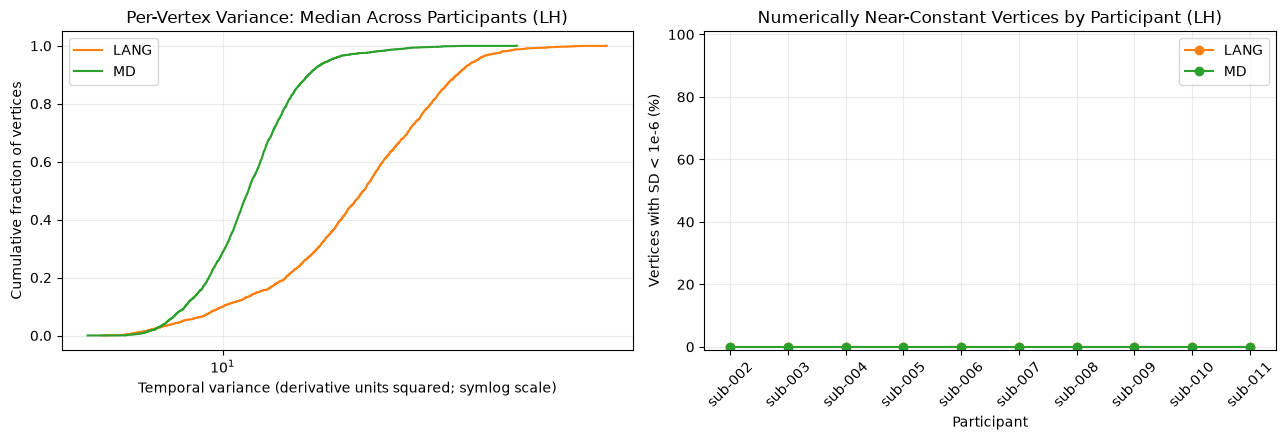

In [41]:
def vertex_temporal_variance(time_series):
    values = np.asarray(time_series, dtype=np.float64)
    if values.ndim != 2 or values.shape[0] < 2 or not np.isfinite(values).all():
        raise ValueError("Expected finite time-by-vertex data with at least two time points.")
    return np.var(values, axis=0, ddof=0)

variance_probe = np.column_stack([np.ones(4), np.arange(4), np.arange(4) + 1000.0])
np.testing.assert_allclose(vertex_temporal_variance(variance_probe), [0.0, 1.25, 1.25])

VARIANCE_QC_SD_EPS = 1e-6
variance_qc_frames = []
for variance_subject in SAMPLE_SUBJECTS:
    for variance_network, variance_mask in [("LANG", mask_LANG_L), ("MD", mask_MD_L)]:
        variance_vertex_ids = np.flatnonzero(variance_mask)
        variance_values = vertex_temporal_variance(clean_runs_L[variance_subject][:, variance_vertex_ids])
        variance_qc_frames.append(pd.DataFrame({
            "participant_id": variance_subject,
            "task": "pieman",
            "hemisphere": "L",
            "vertex_id": variance_vertex_ids,
            "network": variance_network,
            "parcel": [label_dict_L[int(atlas_L[vertex_id])] for vertex_id in variance_vertex_ids],
            "n_TRs": clean_runs_L[variance_subject].shape[0],
            "temporal_variance": variance_values,
            "temporal_sd": np.sqrt(variance_values),
            "near_constant": variance_values < VARIANCE_QC_SD_EPS ** 2,
        }))
df_vertex_variance = pd.concat(variance_qc_frames, ignore_index=True)
assert not df_vertex_variance.duplicated(["participant_id", "hemisphere", "vertex_id"]).any()
assert len(df_vertex_variance) == len(SAMPLE_SUBJECTS) * int(mask_LANG_L.sum() + mask_MD_L.sum())
assert (df_vertex_variance["n_TRs"] == PIEMAN_DUR).all()
assert np.isfinite(df_vertex_variance["temporal_variance"]).all()

df_variance_subject_summary = df_vertex_variance.groupby(["participant_id", "network"]).agg(
    n_vertices=("vertex_id", "size"),
    variance_p10=("temporal_variance", lambda values: values.quantile(0.1)),
    median_variance=("temporal_variance", "median"),
    variance_p90=("temporal_variance", lambda values: values.quantile(0.9)),
    near_constant_vertices=("near_constant", "sum"),
    near_constant_fraction=("near_constant", "mean"),
).reset_index()
df_vertex_variance_summary = df_vertex_variance.groupby(["hemisphere", "vertex_id", "network", "parcel"]).agg(
    n_participants=("participant_id", "nunique"),
    median_variance=("temporal_variance", "median"),
    variance_p10=("temporal_variance", lambda values: values.quantile(0.1)),
    variance_p90=("temporal_variance", lambda values: values.quantile(0.9)),
    near_constant_fraction=("near_constant", "mean"),
).reset_index()

print("=== Step 3B: Per-Vertex Temporal Variance Before Notebook Z-Scoring ===")
print(f"Scope: Pie Man, left hemisphere, {len(SAMPLE_SUBJECTS)} sampled participants, full {PIEMAN_DUR}-TR story window.")
print("Input: AFNI desc-clean derivatives; no additional detrending or z-scoring. Variance uses ddof=0.")
print(f"Near-constant numerical flag: SD < {VARIANCE_QC_SD_EPS:g} (variance < {VARIANCE_QC_SD_EPS ** 2:g}); not a biological cutoff or new gate.")
print("Variance is in derivative units squared, not necessarily percent-signal-change squared.")
print("Larger variance does not establish neural reliability or prediction difficulty.")
display(df_variance_subject_summary)
print(f"Individual measurements: df_vertex_variance ({len(df_vertex_variance):,} rows; first 10 below).")
display(df_vertex_variance.head(10))
print(f"Each vertex summarized across participants: df_vertex_variance_summary ({len(df_vertex_variance_summary):,} rows; first 10 below).")
display(df_vertex_variance_summary.head(10))

variance_figure, variance_axes = plt.subplots(1, 2, figsize=(13, 4.5))
for variance_network, variance_color in [("LANG", "tab:orange"), ("MD", "tab:green")]:
    variance_sorted = np.sort(df_vertex_variance_summary.loc[df_vertex_variance_summary["network"] == variance_network, "median_variance"].to_numpy())
    variance_axes[0].step(variance_sorted, np.arange(1, len(variance_sorted) + 1) / len(variance_sorted), where="post", label=variance_network, color=variance_color)
    variance_subject_rows = df_variance_subject_summary[df_variance_subject_summary["network"] == variance_network]
    variance_axes[1].plot(variance_subject_rows["participant_id"], 100 * variance_subject_rows["near_constant_fraction"], marker="o", label=variance_network, color=variance_color)
variance_axes[0].set_xscale("symlog", linthresh=VARIANCE_QC_SD_EPS ** 2)
variance_axes[0].set_title("Per-Vertex Variance: Median Across Participants (LH)")
variance_axes[0].set_xlabel("Temporal variance (derivative units squared; symlog scale)")
variance_axes[0].set_ylabel("Cumulative fraction of vertices")
variance_axes[1].set_title("Numerically Near-Constant Vertices by Participant (LH)")
variance_axes[1].set_xlabel("Participant")
variance_axes[1].set_ylabel("Vertices with SD < 1e-6 (%)")
variance_axes[1].set_ylim(-1, 101)
variance_axes[1].tick_params(axis="x", rotation=45)
for variance_axis in variance_axes:
    variance_axis.legend()
variance_figure.tight_layout()
plt.show()

## Step 5. Signal Reliability & Noise Ceiling (The Key Feasibility Gate)
**Questions Answered (Step 5 & Q12 Bonus):**
1. **Across-subject Leave-One-Out ISC:** For each vertex $v$ and each parcel $p$ in `EAC`, `LANG`, and `MD`, what is the leave-one-subject-out correlation $\text{ISC}(v)$ and the Spearman–Brown group-mean noise ceiling $\text{NC}_{\text{group}}(v)$?
2. **Key Gate Metric:** How many `MD` vertices and parcels exceed $\text{ISC} > 0.05$ (and $\text{NC}_{\text{group}} > 0.10$)?
3. **Within-Subject vs. Across-Subject Reliability (`run-1` vs. `run-2` on `pieman`):** Because `MD` topography varies across individuals, across-subject ISC underestimates true `MD` reliability. We compare within-subject test–retest correlation $\text{corr}(y_{i,\text{run1}}, y_{i,\text{run2}})$ against across-subject ISC on the repeat-listen subjects (`sub-002`..`sub-006`).

=== Step 5: Corrected Pairwise ISC (rho) vs LOO ISC & True Spearman-Brown Group Ceilings ===
EAC  | Vertex rho=0.0391 (LOO=0.098), Verts rho>0.015:  576/ 808 ( 71.3%) | Parcel rho=0.1466 (LOO=0.296) | Group NC_r (N=10/14/20/75): 0.795 / 0.840 / 0.880 / 0.963
LANG | Vertex rho=0.0132 (LOO=0.037), Verts rho>0.015: 1169/2708 ( 43.2%) | Parcel rho=0.0444 (LOO=0.115) | Group NC_r (N=10/14/20/75): 0.563 / 0.628 / 0.694 / 0.881
MD   | Vertex rho=0.0081 (LOO=0.023), Verts rho>0.015:  882/3405 ( 25.9%) | Parcel rho=0.0229 (LOO=0.063) | Group NC_r (N=10/14/20/75): 0.435 / 0.497 / 0.565 / 0.798


,network,parcel,pairwise_rho_trim,loo_ISC_trim_N10,NC_var_N10,NC_r_N10,NC_r_N14,NC_r_N20,NC_r_N75,rho_gt_0.015
0,EAC,A1,0.2024,0.3790,0.7173,0.8469,0.8834,0.9140,0.9747,True
1,EAC,LBelt,0.1748,0.3434,0.6792,0.8242,0.8647,0.8994,0.9699,True
2,EAC,MBelt,0.1179,0.2585,0.5721,0.7564,0.8073,0.8531,0.9536,True
3,EAC,PBelt,0.1733,0.3421,0.6770,0.8228,0.8636,0.8986,0.9696,True
4,EAC,RI,0.0644,0.1584,0.4078,0.6386,0.7006,0.7612,0.9153,True
5,LANG,44,0.0588,0.1486,0.3846,0.6201,0.6831,0.7453,0.9078,True
6,LANG,45,0.0503,0.1298,0.3462,0.5884,0.6525,0.7172,0.8938,True
7,LANG,47l,0.0325,0.0883,0.2515,0.5015,0.5656,0.6340,0.8461,True
8,LANG,55b,0.0511,0.1329,0.3500,0.5916,0.6556,0.7201,0.8953,True
9,LANG,STGa,0.0205,0.0582,0.1731,0.4161,0.4761,0.5433,0.7816,True



=== Step 5B: Within-Subject Repeat r (run-1 vs run-2) vs Across-Subject Pairwise ISC (rho) ===
  EAC : Within-Subject Repeat r = 0.2593  |  Across-Subject Pairwise rho = 0.1466 (Idiosyncratic gap = +0.1127, Within/Pairwise ratio = 1.77x)  |  N=10 LOO ISC = 0.2963
  LANG: Within-Subject Repeat r = 0.1086  |  Across-Subject Pairwise rho = 0.0444 (Idiosyncratic gap = +0.0642, Within/Pairwise ratio = 2.45x)  |  N=10 LOO ISC = 0.1152
  MD  : Within-Subject Repeat r = 0.0569  |  Across-Subject Pairwise rho = 0.0229 (Idiosyncratic gap = +0.0341, Within/Pairwise ratio = 2.49x)  |  N=10 LOO ISC = 0.0629


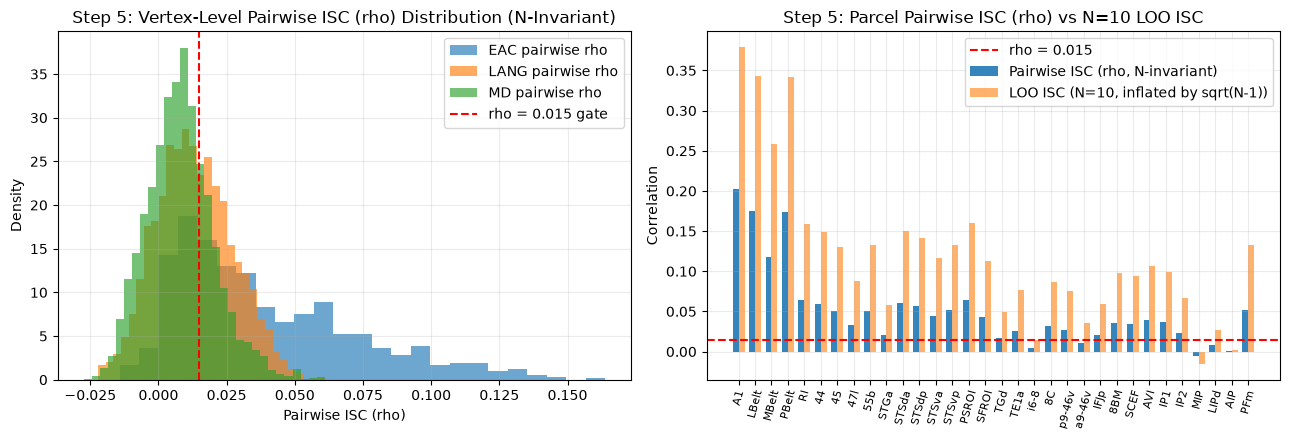

In [19]:
def zscore_time(Y: np.ndarray, detrend_linear: bool = True) -> np.ndarray:
    """Optionally remove linear trend and z-score each column along time axis 0."""
    Y_work = np.asarray(Y, dtype=np.float32)
    if Y_work.ndim == 1:
        Y_work = Y_work[:, None]
        squeeze = True
    else:
        squeeze = False
    if detrend_linear and Y_work.shape[0] > 4:
        t = np.linspace(-1.0, 1.0, Y_work.shape[0], dtype=np.float32)[:, None]
        t = t - t.mean()
        slope = (t.T @ Y_work) / float((t.T @ t)[0, 0])
        Y_work = Y_work - t @ slope
    mu = Y_work.mean(axis=0, keepdims=True)
    sd = Y_work.std(axis=0, keepdims=True)
    out = np.where(sd > 1e-6, (Y_work - mu) / np.where(sd > 1e-6, sd, 1.0), 0.0)
    return out[:, 0] if squeeze else out

def compute_pairwise_and_loo_isc(data_stack: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    data_stack: shape (N_subj, T, V), already z-scored along time axis 1 (mean=0, std=1 per subject).
    Returns:
      - pairwise_rho: N-invariant mean pairwise correlation across all N(N-1)/2 pairs:
                      ((1/T) * sum_t S(t)^2 - N) / (N * (N - 1))
      - loo_isc:      Leave-One-Out correlation r(z_i, mean_{j!=i} z_j) (depends on N!)
      - nc_group_var: True Spearman-Brown group-mean reliable variance fraction from pairwise_rho:
                      (N * rho) / (1 + (N - 1) * rho)
      - nc_group_r:   True group-mean correlation noise ceiling: sqrt(nc_group_var)
    """
    N, T, V = data_stack.shape
    sum_all = data_stack.sum(axis=0)  # S(t), shape (T, V)
    # Fast exact O(N*T*V) pairwise ISC formula
    mean_S2 = np.mean(sum_all ** 2, axis=0)  # (1/T) * sum_t S(t)^2
    pairwise_rho = (mean_S2 - float(N)) / float(N * (N - 1))

    # Also compute LOO ISC for comparison
    isc_per_sub = np.zeros((N, V), dtype=np.float32)
    for i in range(N):
        others_mean = (sum_all - data_stack[i]) / (N - 1)
        others_z = zscore_time(others_mean, detrend_linear=False)
        isc_per_sub[i] = (data_stack[i] * others_z).mean(axis=0)
    loo_isc = isc_per_sub.mean(axis=0)

    pos_rho = np.clip(pairwise_rho, 0.0, 0.999)
    nc_group_var = (N * pos_rho) / (1.0 + (N - 1) * pos_rho)
    nc_group_r = np.sqrt(nc_group_var)
    return pairwise_rho.astype(np.float32), loo_isc.astype(np.float32), nc_group_var.astype(np.float32), nc_group_r.astype(np.float32)

def group_nc_from_pairwise(rho: np.ndarray | float, N: int) -> tuple[np.ndarray | float, np.ndarray | float]:
    """Return (NC_group_var, NC_group_r) at sample size N from N-invariant pairwise ISC rho."""
    pos_rho = np.clip(rho, 0.0, 0.999)
    nc_var = (N * pos_rho) / (1.0 + (N - 1) * pos_rho)
    return nc_var, np.sqrt(nc_var)

# 5A. Vertex-level and Parcel-level Pairwise ISC vs LOO ISC: Full (281 TRs) vs Trimmed ([10 : -5] -> 266 TRs)
TRIM_START_TRS = 10  # trim first 15.0s
TRIM_END_TRS = 5     # trim last 7.5s

stack_L_full = np.stack([zscore_time(clean_runs_L[s]) for s in SAMPLE_SUBJECTS], axis=0)
stack_L_trim = np.stack([zscore_time(clean_runs_L[s][TRIM_START_TRS : PIEMAN_DUR - TRIM_END_TRS]) for s in SAMPLE_SUBJECTS], axis=0)

vertex_rho_L_full, vertex_isc_L, _, _ = compute_pairwise_and_loo_isc(stack_L_full)
vertex_rho_L_trim, vertex_isc_L_trim, vertex_nc_var_L_trim, vertex_nc_r_L_trim = compute_pairwise_and_loo_isc(stack_L_trim)

ALL_PARCELS = [("EAC", p) for p in EAC_PARCELS] + [("LANG", p) for p in LANG_PARCELS] + [("MD", p) for p in MD_PARCELS]
parcel_ts_stack = np.zeros((len(SAMPLE_SUBJECTS), PIEMAN_DUR, len(ALL_PARCELS)), dtype=np.float32)
parcel_ts_stack_trim = np.zeros((len(SAMPLE_SUBJECTS), PIEMAN_DUR - TRIM_START_TRS - TRIM_END_TRS, len(ALL_PARCELS)), dtype=np.float32)

for p_idx, (net, pname) in enumerate(ALL_PARCELS):
    pmask = (atlas_L == name_to_id[pname])
    for s_idx, sub_id in enumerate(SAMPLE_SUBJECTS):
        raw_p = clean_runs_L[sub_id][:, pmask].mean(axis=1)
        parcel_ts_stack[s_idx, :, p_idx] = zscore_time(raw_p)
        parcel_ts_stack_trim[s_idx, :, p_idx] = zscore_time(raw_p[TRIM_START_TRS : PIEMAN_DUR - TRIM_END_TRS])

parcel_rho_full, parcel_isc, _, _ = compute_pairwise_and_loo_isc(parcel_ts_stack)
parcel_rho_trim, parcel_isc_trim, parcel_nc_var_trim, parcel_nc_r_trim = compute_pairwise_and_loo_isc(parcel_ts_stack_trim)

# Projected group correlation ceiling at N=14, N=20, N=75 from N-invariant pairwise_rho
_, nc_r_N14 = group_nc_from_pairwise(parcel_rho_trim, 14)
_, nc_r_N20 = group_nc_from_pairwise(parcel_rho_trim, 20)
_, nc_r_N75 = group_nc_from_pairwise(parcel_rho_trim, 75)

# Note on N-invariant threshold: LOO ISC = 0.05 at N=10 corresponds to pairwise rho ≈ 0.015 (since LOO ≈ sqrt(9*0.015 / (1+8*0.015))*sqrt(0.015) ≈ 0.043, or rho >= 0.015)
RHO_GATE = 0.015

df_parcel_isc = pd.DataFrame({
    "network": [x[0] for x in ALL_PARCELS],
    "parcel": [x[1] for x in ALL_PARCELS],
    "pairwise_rho_trim": np.round(parcel_rho_trim, 4),
    "loo_ISC_trim_N10": np.round(parcel_isc_trim, 4),
    "NC_var_N10": np.round(parcel_nc_var_trim, 4),
    "NC_r_N10": np.round(parcel_nc_r_trim, 4),
    "NC_r_N14": np.round(nc_r_N14, 4),
    "NC_r_N20": np.round(nc_r_N20, 4),
    "NC_r_N75": np.round(nc_r_N75, 4),
    "rho_gt_0.015": parcel_rho_trim > RHO_GATE,
})

print("=== Step 5: Corrected Pairwise ISC (rho) vs LOO ISC & True Spearman-Brown Group Ceilings ===")
for net_name, vmask in [("EAC", mask_EAC_L), ("LANG", mask_LANG_L), ("MD", mask_MD_L)]:
    v_rho = vertex_rho_L_trim[vmask]
    v_loo = vertex_isc_L_trim[vmask]
    p_sub = df_parcel_isc[df_parcel_isc["network"] == net_name]
    mean_rho = float(p_sub["pairwise_rho_trim"].mean())
    _, c10 = group_nc_from_pairwise(mean_rho, 10)
    _, c14 = group_nc_from_pairwise(mean_rho, 14)
    _, c20 = group_nc_from_pairwise(mean_rho, 20)
    _, c75 = group_nc_from_pairwise(mean_rho, 75)
    print(
        f"{net_name:4s} | Vertex rho={v_rho.mean():.4f} (LOO={v_loo.mean():.3f}), Verts rho>0.015: {(v_rho > RHO_GATE).sum():4d}/{len(v_rho):4d} ({(v_rho > RHO_GATE).mean()*100:5.1f}%) | "
        f"Parcel rho={mean_rho:.4f} (LOO={p_sub['loo_ISC_trim_N10'].mean():.3f}) | "
        f"Group NC_r (N=10/14/20/75): {c10:.3f} / {c14:.3f} / {c20:.3f} / {c75:.3f}"
    )

display(df_parcel_isc)

# 5B. Compare N-invariant Pairwise ISC (rho) vs Within-Subject Repeat Reliability (run-1 vs run-2)
REPEAT_SUBS = ["sub-002", "sub-003", "sub-004", "sub-005", "sub-006"]
within_corrs_trim = {"EAC": [], "LANG": [], "MD": []}
for sub_id in REPEAT_SUBS:
    r2_path = fetch_subject_pieman_surface(sub_id, "2", "L", "clean")
    g2 = nib.load(str(r2_path))
    Y_r2 = np.vstack([da.data for da in g2.darrays]).astype(np.float32)[PIEMAN_ONSET : PIEMAN_ONSET + PIEMAN_DUR]
    Y_r1 = clean_runs_L[sub_id]
    for net_name, plist in [("EAC", EAC_PARCELS), ("LANG", LANG_PARCELS), ("MD", MD_PARCELS)]:
        p_corrs = []
        for pname in plist:
            pmask = (atlas_L == name_to_id[pname])
            ts1 = zscore_time(Y_r1[TRIM_START_TRS : PIEMAN_DUR - TRIM_END_TRS, pmask].mean(axis=1))
            ts2 = zscore_time(Y_r2[TRIM_START_TRS : PIEMAN_DUR - TRIM_END_TRS, pmask].mean(axis=1))
            p_corrs.append(float(np.mean(ts1 * ts2)))
        within_corrs_trim[net_name].append(np.mean(p_corrs))

print("\n=== Step 5B: Within-Subject Repeat r (run-1 vs run-2) vs Across-Subject Pairwise ISC (rho) ===")
for net_name in ["EAC", "LANG", "MD"]:
    p_sub = df_parcel_isc[df_parcel_isc["network"] == net_name]
    rho_val = float(p_sub["pairwise_rho_trim"].mean())
    loo_val = float(p_sub["loo_ISC_trim_N10"].mean())
    within_val = float(np.mean(within_corrs_trim[net_name]))
    idiosyncratic_gap = within_val - rho_val
    print(
        f"  {net_name:4s}: Within-Subject Repeat r = {within_val:.4f}  |  Across-Subject Pairwise rho = {rho_val:.4f} "
        f"(Idiosyncratic gap = {idiosyncratic_gap:+.4f}, Within/Pairwise ratio = {within_val / max(rho_val, 1e-6):.2f}x)  |  N=10 LOO ISC = {loo_val:.4f}"
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(vertex_rho_L_trim[mask_EAC_L], bins=25, alpha=0.65, label="EAC pairwise rho", density=True)
axes[0].hist(vertex_rho_L_trim[mask_LANG_L], bins=30, alpha=0.65, label="LANG pairwise rho", density=True)
axes[0].hist(vertex_rho_L_trim[mask_MD_L], bins=30, alpha=0.65, label="MD pairwise rho", density=True)
axes[0].axvline(RHO_GATE, color="red", linestyle="--", label=f"rho = {RHO_GATE} gate")
axes[0].set_title("Step 5: Vertex-Level Pairwise ISC (rho) Distribution (N-Invariant)")
axes[0].set_xlabel("Pairwise ISC (rho)")
axes[0].set_ylabel("Density")
axes[0].legend()

x_idx = np.arange(len(df_parcel_isc))
axes[1].bar(x_idx - 0.18, df_parcel_isc["pairwise_rho_trim"], width=0.36, alpha=0.9, label="Pairwise ISC (rho, N-invariant)")
axes[1].bar(x_idx + 0.18, df_parcel_isc["loo_ISC_trim_N10"], width=0.36, alpha=0.6, label="LOO ISC (N=10, inflated by sqrt(N-1))")
axes[1].axhline(RHO_GATE, color="red", linestyle="--", label=f"rho = {RHO_GATE}")
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(df_parcel_isc["parcel"], rotation=75, fontsize=8)
axes[1].set_title("Step 5: Parcel Pairwise ISC (rho) vs N=10 LOO ISC")
axes[1].set_ylabel("Correlation")
axes[1].legend()
plt.tight_layout()
plt.show()

## Step 2B & Step 6. Hemodynamic Delay Verification & Simple Lexical Baselines
**Questions Answered (Step 2 Lag Check & Step 6 Baselines):**
1. **Hemodynamic Delay Sanity Check:** Since $\text{TR} = 1.5\text{ s}$ in Narratives, which TR lag ($0..6$ TRs $= 0..9\text{ s}$) maximizes the correlation between speech rate / word activity and **Early Auditory Cortex (EAC)** BOLD?
2. **Simple Baselines (Word Rate, Word Length, Unigram Surprisal):** How strongly do simple non-LLM lexical features already predict group-mean `EAC`, `LANG`, and `MD` time courses (using split-half temporal cross-validation)?

=== Step 2B: Empirical EAC Peak Lag = 1 TRs (1.5 s), r = 0.352 ===
=== Step 6: Low-Level Acoustic/Lexical Baseline (Lags 1,2,3,4 TRs; Transient-Trimmed Split-Half CV) ===
  EAC  Mean Parcel r (unweighted, all 5)     : 0.388 (max = 0.527)
  LANG Mean Parcel r (unweighted, all 13)    : 0.019 (max = 0.241)
  MD   Mean Parcel r (unweighted, all 14)    : 0.097 (pairwise-rho-weighted all 14 = 0.099, max = 0.256)


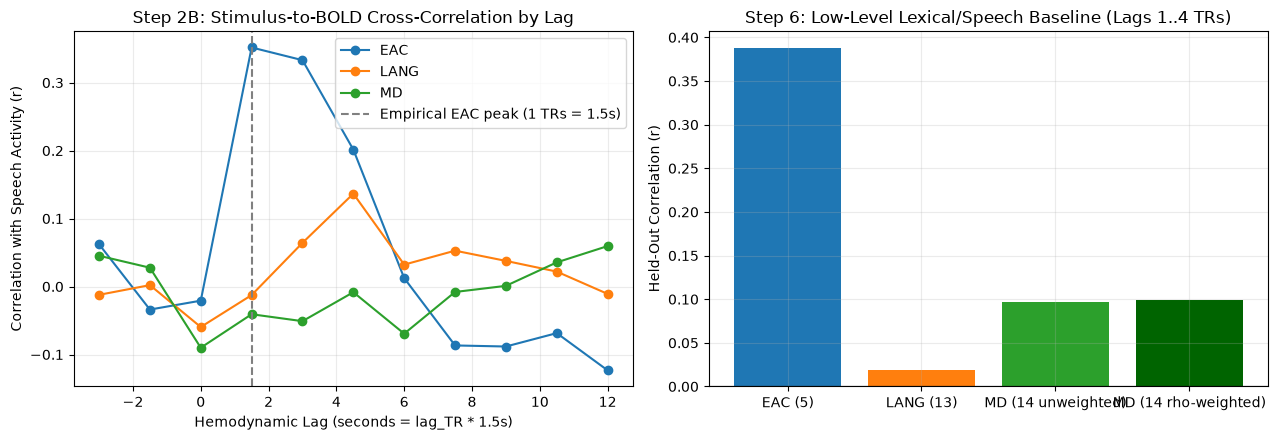

In [20]:
# Use transient-trimmed group-mean parcel time series across sample subjects: shape (T_trim=266, n_parcels=32)
T_TRIM = PIEMAN_DUR - TRIM_START_TRS - TRIM_END_TRS
group_parcel_ts = zscore_time(parcel_ts_stack_trim.mean(axis=0))
idx_EAC = [i for i, (n, _) in enumerate(ALL_PARCELS) if n == "EAC"]
idx_LANG = [i for i, (n, _) in enumerate(ALL_PARCELS) if n == "LANG"]
idx_MD = [i for i, (n, _) in enumerate(ALL_PARCELS) if n == "MD"]

mean_EAC_ts = zscore_time(group_parcel_ts[:, idx_EAC].mean(axis=1))
mean_LANG_ts = zscore_time(group_parcel_ts[:, idx_LANG].mean(axis=1))
mean_MD_ts = zscore_time(group_parcel_ts[:, idx_MD].mean(axis=1))

# Build TR-level simple lexical features for pieman (281 TRs), subtracting the 15s (10-TR) WAV lead-in,
# then slice to the exact same transient-trimmed window [TRIM_START_TRS : PIEMAN_DUR - TRIM_END_TRS]
df_pieman_w = load_gentle_align("pieman").dropna(subset=["start_sec"]).copy()
df_pieman_w["story_rel_sec"] = df_pieman_w["start_sec"] - (PIEMAN_ONSET * 1.5)
df_pieman_w["tr_bin"] = np.floor(df_pieman_w["story_rel_sec"] / 1.5).astype(int)
df_pieman_w = df_pieman_w[(df_pieman_w["tr_bin"] >= 0) & (df_pieman_w["tr_bin"] < PIEMAN_DUR)]
df_pieman_w["word_clean"] = df_pieman_w["word"].astype(str).str.lower().str.replace(r"[^a-z']", "", regex=True)
df_pieman_w["word_len"] = df_pieman_w["word_clean"].str.len()

word_counts = df_pieman_w["word_clean"].value_counts()
df_pieman_w["unigram_surprisal"] = -np.log2((df_pieman_w["word_clean"].map(word_counts) + 1.0) / (len(df_pieman_w) + len(word_counts)))

feat_word_rate = np.zeros(PIEMAN_DUR, dtype=np.float32)
feat_word_len = np.zeros(PIEMAN_DUR, dtype=np.float32)
feat_surprisal = np.zeros(PIEMAN_DUR, dtype=np.float32)
feat_voiced_frac = np.zeros(PIEMAN_DUR, dtype=np.float32)

for tr_i, grp in df_pieman_w.groupby("tr_bin"):
    feat_word_rate[tr_i] = len(grp)
    feat_word_len[tr_i] = grp["word_len"].mean()
    feat_surprisal[tr_i] = grp["unigram_surprisal"].sum()
    feat_voiced_frac[tr_i] = np.clip((grp["end_sec"] - grp["start_sec"]).sum() / 1.5, 0.0, 1.0)

# Slice features to the transient-trimmed window [10 : 276]
sl_trim = slice(TRIM_START_TRS, PIEMAN_DUR - TRIM_END_TRS)
feat_word_rate_t = feat_word_rate[sl_trim]
feat_word_len_t = feat_word_len[sl_trim]
feat_surprisal_t = feat_surprisal[sl_trim]
feat_voiced_frac_t = feat_voiced_frac[sl_trim]

# 2B. Lagged cross-correlation between speech activity (voiced_frac) and EAC, LANG, MD across lags -2..+8 TRs
lags = np.arange(-2, 9)
lag_corrs = {"EAC": [], "LANG": [], "MD": []}
stim_driver = zscore_time(feat_voiced_frac_t)

for L in lags:
    if L >= 0:
        s_slice = stim_driver[: T_TRIM - L]
        eac_slice, lang_slice, md_slice = mean_EAC_ts[L:], mean_LANG_ts[L:], mean_MD_ts[L:]
    else:
        s_slice = stim_driver[-L:]
        eac_slice, lang_slice, md_slice = mean_EAC_ts[: T_TRIM + L], mean_LANG_ts[: T_TRIM + L], mean_MD_ts[: T_TRIM + L]
    lag_corrs["EAC"].append(float(np.corrcoef(s_slice, eac_slice)[0, 1]))
    lag_corrs["LANG"].append(float(np.corrcoef(s_slice, lang_slice)[0, 1]))
    lag_corrs["MD"].append(float(np.corrcoef(s_slice, md_slice)[0, 1]))

best_eac_lag = lags[int(np.argmax(lag_corrs["EAC"]))]
print(f"=== Step 2B: Empirical EAC Peak Lag = {best_eac_lag} TRs ({best_eac_lag * 1.5:.1f} s), r = {max(lag_corrs['EAC']):.3f} ===")

# Step 6: 2-fold contiguous split-half ridge baseline using IDENTICAL lags [1, 2, 3, 4] TRs (1.5..6.0s) as locked config
LOCKED_LAGS = [1, 2, 3, 4]
X_base_raw = zscore_time(np.column_stack([feat_voiced_frac_t, feat_word_rate_t, feat_word_len_t, feat_surprisal_t]))
X_lagged = np.hstack([np.roll(X_base_raw, k, axis=0) for k in LOCKED_LAGS])
X_lagged[: max(LOCKED_LAGS)] = 0.0

mid_t = T_TRIM // 2
Y_pred_base = np.zeros_like(group_parcel_ts)
alpha = 100.0
for tr_idx, te_idx in [(slice(0, mid_t), slice(mid_t, T_TRIM)), (slice(mid_t, T_TRIM), slice(0, mid_t))]:
    Xtr, Ytr = zscore_time(X_lagged[tr_idx]), zscore_time(group_parcel_ts[tr_idx])
    Xte = zscore_time(X_lagged[te_idx])
    W = np.linalg.solve(Xtr.T @ Xtr + alpha * np.eye(Xtr.shape[1]), Xtr.T @ Ytr)
    Y_pred_base[te_idx] = Xte @ W

r_base = np.array([np.corrcoef(group_parcel_ts[:, j], Y_pred_base[:, j])[0, 1] for j in range(group_parcel_ts.shape[1])])
# N-invariant parcel weights from pairwise_rho: w_p proportional to max(pairwise_rho, 0)
w_md = np.clip(parcel_rho_trim[idx_MD], 0.0, None)
w_md = w_md / max(w_md.sum(), 1e-8)

print("=== Step 6: Low-Level Acoustic/Lexical Baseline (Lags 1,2,3,4 TRs; Transient-Trimmed Split-Half CV) ===")
print(f"  EAC  Mean Parcel r (unweighted, all 5)     : {r_base[idx_EAC].mean():.3f} (max = {r_base[idx_EAC].max():.3f})")
print(f"  LANG Mean Parcel r (unweighted, all 13)    : {r_base[idx_LANG].mean():.3f} (max = {r_base[idx_LANG].max():.3f})")
print(f"  MD   Mean Parcel r (unweighted, all 14)    : {r_base[idx_MD].mean():.3f} (pairwise-rho-weighted all 14 = {float(np.sum(r_base[idx_MD] * w_md)):.3f}, max = {r_base[idx_MD].max():.3f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for net_name, c in [("EAC", "tab:blue"), ("LANG", "tab:orange"), ("MD", "tab:green")]:
    axes[0].plot(lags * 1.5, lag_corrs[net_name], marker="o", label=net_name, color=c)
axes[0].axvline(best_eac_lag * 1.5, color="gray", linestyle="--", label=f"Empirical EAC peak ({best_eac_lag} TRs = {best_eac_lag*1.5:.1f}s)")
axes[0].set_title("Step 2B: Stimulus-to-BOLD Cross-Correlation by Lag")
axes[0].set_xlabel("Hemodynamic Lag (seconds = lag_TR * 1.5s)")
axes[0].set_ylabel("Correlation with Speech Activity (r)")
axes[0].legend()

axes[1].bar(
    ["EAC (5)", "LANG (13)", "MD (14 unweighted)", "MD (14 rho-weighted)"],
    [r_base[idx_EAC].mean(), r_base[idx_LANG].mean(), r_base[idx_MD].mean(), float(np.sum(r_base[idx_MD] * w_md))],
    color=["tab:blue", "tab:orange", "tab:green", "darkgreen"],
)
axes[1].axhline(0.0, color="black", lw=0.8)
axes[1].set_title("Step 6: Low-Level Lexical/Speech Baseline (Lags 1..4 TRs)")
axes[1].set_ylabel("Held-Out Correlation (r)")
plt.tight_layout()
plt.show()

## Step 7. Empirical LANG–MD Relationship & Consecutive-TR Autocorrelation
**Questions Answered (Q9, Q11 & Step 7):**
1. **Q11 (How correlated are LANG and MD outputs?):**
   * What is the network-mean correlation $\text{corr}(\bar{y}_{\text{LANG}}(t), \bar{y}_{\text{MD}}(t))$?
   * What does the full $13 \times 14$ parcel-by-parcel cross-correlation matrix $C_{\text{LANG} \times \text{MD}}$ look like?
   * How much variance in `MD` remains after regressing out `LANG` across lags $(0, 1, 2)$ TRs?
2. **Q9 (Consecutive-TR autocorrelation & permutation block length):**
   * How strongly correlated are consecutive TRs ($t, t+1, \dots$) in `LANG`, `MD`, and `MD_residual`?
   * At what lag $L_{\text{decorr}}$ does autocorrelation drop below $0.1$, setting the minimum block/shift size for permutation testing?

=== Step 7 (Q11): Pairwise-ISC Corrected Reliable Variance Decomposition of MD (N=10, Transient-Trimmed) ===
  Network-mean corr(mean_LANG, mean_MD)                    : +0.127
  Parcel-pair corr(LANG_i, MD_j) min / med / max           : -0.271 / +0.027 / +0.530
  Mean MD pairwise ISC (rho, N-invariant)                  : 0.0229
  True MD group-mean reliable variance at N=10 (NC_var)    : 0.179 (noise floor = 0.821, NC_r = 0.423)
  Same-cohort lagged LANG -> MD R^2 (mean r = 0.292)       : 0.118 (includes shared same-subject noise)
  Same-cohort reliable MD variance unexplained by LANG     : 0.061 (34.1% of reliable MD variance)
  Low-level baseline r on Residual MD (all 14 / rho-wtd)   : 0.025 / 0.039

=== Step 7B (Q9): Consecutive-TR Autocorrelation & Permutation Block Size ===
  Lag-1 autocorrelation rho_1 (LANG / MD / MD_resid)       : 0.741 / 0.638 / 0.630
  First lag where |ACF(MD_resid)| < 0.1                    : 5 TRs (7.5 s) -> min circular shift >= 10 TRs (15 s)


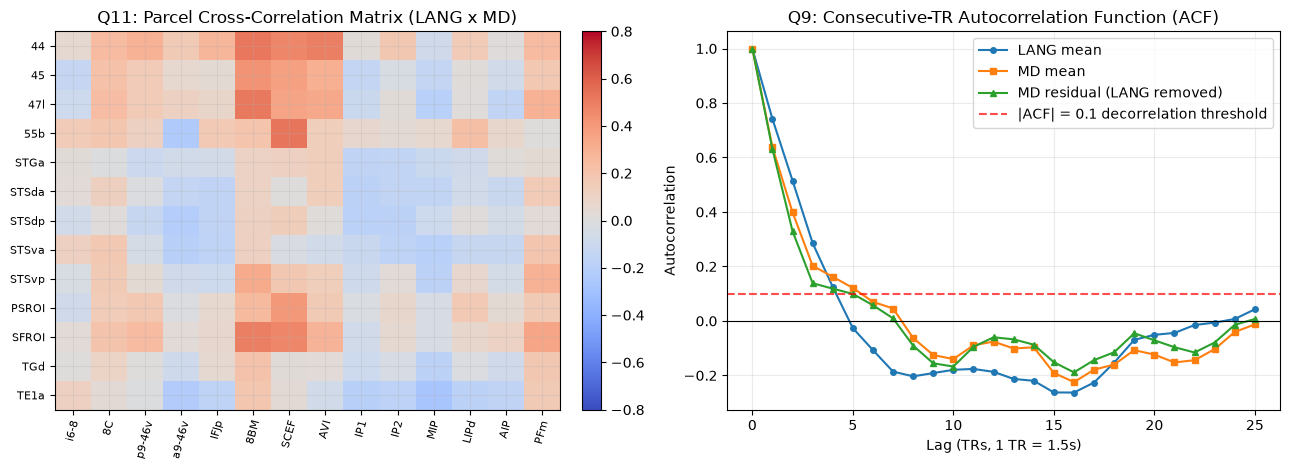

In [21]:
# 7A. Network-mean and parcel-by-parcel cross-correlation between LANG and MD (Q11) on transient-trimmed window
Y_LANG = group_parcel_ts[:, idx_LANG]  # (266, 13)
Y_MD = group_parcel_ts[:, idx_MD]      # (266, 14)

net_mean_corr = float(np.corrcoef(mean_LANG_ts, mean_MD_ts)[0, 1])
C_lang_md = (zscore_time(Y_LANG).T @ zscore_time(Y_MD)) / len(Y_LANG)  # (13, 14)

# Multi-lag cross-validated ridge residualization of MD on LANG (lags 0, 1, 2 TRs)
Y_LANG_lags = np.hstack([np.roll(Y_LANG, k, axis=0) for k in [0, 1, 2]])
Y_LANG_lags[:2] = 0.0
Y_MD_hat_from_LANG = np.zeros_like(Y_MD)
for tr_idx, te_idx in [(slice(0, mid_t), slice(mid_t, T_TRIM)), (slice(mid_t, T_TRIM), slice(0, mid_t))]:
    Ztr, Ytr = zscore_time(Y_LANG_lags[tr_idx]), zscore_time(Y_MD[tr_idx])
    Zte = zscore_time(Y_LANG_lags[te_idx])
    W_lm = np.linalg.solve(Ztr.T @ Ztr + 50.0 * np.eye(Ztr.shape[1]), Ztr.T @ Ytr)
    Y_MD_hat_from_LANG[te_idx] = Zte @ W_lm

Y_MD_resid = zscore_time(Y_MD - Y_MD_hat_from_LANG)
r_lang_to_md = np.array([np.corrcoef(Y_MD[:, j], Y_MD_hat_from_LANG[:, j])[0, 1] for j in range(Y_MD.shape[1])])
r2_lang_to_md = np.clip(r_lang_to_md, 0.0, None) ** 2

# EXACT PAIRWISE-ISC RELIABLE VARIANCE DECOMPOSITION:
# True group-mean reliable variance at N=10 is NC_group_var = (N * pairwise_rho) / (1 + (N - 1) * pairwise_rho)
nc_md_var_N10 = parcel_nc_var_trim[idx_MD]
mean_nc_var_N10 = float(nc_md_var_N10.mean())
mean_r2_same_cohort = float(r2_lang_to_md.mean())
rem_reliable_same_cohort = max(mean_nc_var_N10 - mean_r2_same_cohort, 0.0)
pct_reliable_unexplained_same = (rem_reliable_same_cohort / max(mean_nc_var_N10, 1e-8)) * 100.0

# Also test predicting Y_MD_resid from the low-level acoustic/lexical baseline (X_lagged, lags 1..4)
Y_MD_resid_hat_base = np.zeros_like(Y_MD_resid)
for tr_idx, te_idx in [(slice(0, mid_t), slice(mid_t, T_TRIM)), (slice(mid_t, T_TRIM), slice(0, mid_t))]:
    Xtr, Ytr = zscore_time(X_lagged[tr_idx]), zscore_time(Y_MD_resid[tr_idx])
    Xte = zscore_time(X_lagged[te_idx])
    W_rb = np.linalg.solve(Xtr.T @ Xtr + alpha * np.eye(Xtr.shape[1]), Xtr.T @ Ytr)
    Y_MD_resid_hat_base[te_idx] = Xte @ W_rb
r_base_on_md_resid = np.array([np.corrcoef(Y_MD_resid[:, j], Y_MD_resid_hat_base[:, j])[0, 1] for j in range(Y_MD_resid.shape[1])])

print("=== Step 7 (Q11): Pairwise-ISC Corrected Reliable Variance Decomposition of MD (N=10, Transient-Trimmed) ===")
print(f"  Network-mean corr(mean_LANG, mean_MD)                    : {net_mean_corr:+.3f}")
print(f"  Parcel-pair corr(LANG_i, MD_j) min / med / max           : {C_lang_md.min():+.3f} / {np.median(C_lang_md):+.3f} / {C_lang_md.max():+.3f}")
print(f"  Mean MD pairwise ISC (rho, N-invariant)                  : {float(parcel_rho_trim[idx_MD].mean()):.4f}")
print(f"  True MD group-mean reliable variance at N=10 (NC_var)    : {mean_nc_var_N10:.3f} (noise floor = {1.0 - mean_nc_var_N10:.3f}, NC_r = {np.sqrt(mean_nc_var_N10):.3f})")
print(f"  Same-cohort lagged LANG -> MD R^2 (mean r = {r_lang_to_md.mean():.3f})       : {mean_r2_same_cohort:.3f} (includes shared same-subject noise)")
print(f"  Same-cohort reliable MD variance unexplained by LANG     : {rem_reliable_same_cohort:.3f} ({pct_reliable_unexplained_same:.1f}% of reliable MD variance)")
print(f"  Low-level baseline r on Residual MD (all 14 / rho-wtd)   : {r_base_on_md_resid.mean():.3f} / {float(np.sum(r_base_on_md_resid * w_md)):.3f}")

# 7B. Consecutive-TR Autocorrelation Function (ACF) up to 25 TRs (Q9)
def compute_acf(ts_1d: np.ndarray, max_lag: int = 25) -> np.ndarray:
    z = zscore_time(ts_1d)
    acfs = [1.0]
    for k in range(1, max_lag + 1):
        acfs.append(float(np.mean(z[:-k] * z[k:])))
    return np.array(acfs)

max_lag = 25
acf_LANG = compute_acf(mean_LANG_ts, max_lag)
acf_MD = compute_acf(mean_MD_ts, max_lag)
acf_MD_resid = compute_acf(Y_MD_resid.mean(axis=1), max_lag)

decorr_lag_md = int(np.argmax(np.abs(acf_MD_resid) < 0.1))
print("\n=== Step 7B (Q9): Consecutive-TR Autocorrelation & Permutation Block Size ===")
print(f"  Lag-1 autocorrelation rho_1 (LANG / MD / MD_resid)       : {acf_LANG[1]:.3f} / {acf_MD[1]:.3f} / {acf_MD_resid[1]:.3f}")
print(f"  First lag where |ACF(MD_resid)| < 0.1                    : {decorr_lag_md} TRs ({decorr_lag_md * 1.5:.1f} s) -> min circular shift >= 10 TRs (15 s)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
im = axes[0].imshow(C_lang_md, cmap="coolwarm", vmin=-0.8, vmax=0.8, aspect="auto")
axes[0].set_xticks(range(len(MD_PARCELS)))
axes[0].set_xticklabels(MD_PARCELS, rotation=75, fontsize=8)
axes[0].set_yticks(range(len(LANG_PARCELS)))
axes[0].set_yticklabels(LANG_PARCELS, fontsize=8)
axes[0].set_title("Q11: Parcel Cross-Correlation Matrix (LANG x MD)")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

lag_axis = np.arange(0, max_lag + 1)
axes[1].plot(lag_axis, acf_LANG, marker="o", markersize=4, label="LANG mean")
axes[1].plot(lag_axis, acf_MD, marker="s", markersize=4, label="MD mean")
axes[1].plot(lag_axis, acf_MD_resid, marker="^", markersize=4, label="MD residual (LANG removed)")
axes[1].axhline(0.1, color="red", linestyle="--", alpha=0.7, label="|ACF| = 0.1 decorrelation threshold")
axes[1].axhline(0.0, color="black", lw=0.8)
axes[1].set_title("Q9: Consecutive-TR Autocorrelation Function (ACF)")
axes[1].set_xlabel("Lag (TRs, 1 TR = 1.5s)")
axes[1].set_ylabel("Autocorrelation")
axes[1].legend()
plt.tight_layout()
plt.show()

## Step 8. Feature-Side Diagnostics (5-TR Context Windows, Story Text Leakage & GPT-2 Layer Spectrum)
**Questions Answered (Step 8):**
1. How many words fall inside a **5-TR ($7.5\text{ s}$) sliding context window** across stories?
2. **Train/Test Text Leakage Audit:** What is the pairwise 4-gram Jaccard overlap across stories (`pieman`, `tunnel`, `lucy`, `prettymouth`, `milkywayoriginal`, `notthefallintact`, `21styear`, `merlin`, `sherlock`)?
3. What does the singular-value / PCA cumulative explained-variance spectrum of GPT-2 look like across layers (if `transformers` + `torch` are available)?

In [10]:
# 8A. 5-TR (7.5s) Context Window Word Counts & Pairwise 4-gram Text Leakage Matrix
story_4grams = {}
window_stats = []

for st in CORE_STORIES:
    w_counts = tr_word_Series_by_story[st]
    # 5-TR sliding sum
    win5 = np.convolve(w_counts, np.ones(5, dtype=int), mode="valid")
    df_w = load_gentle_align(st)
    tokens = [re.sub(r"[^a-z0-9]", "", str(w).lower()) for w in df_w["word"].dropna()]
    tokens = [t for t in tokens if t]
    ngrams = set(zip(tokens[:-3], tokens[1:-2], tokens[2:-1], tokens[3:]))
    story_4grams[st] = ngrams

    window_stats.append({
        "story": st,
        "mean_words_per_5TR_window": round(float(win5.mean()), 1),
        "p10_words_5TR": int(np.percentile(win5, 10)),
        "p90_words_5TR": int(np.percentile(win5, 90)),
        "empty_5TR_windows_pct": round(float((win5 == 0).mean() * 100), 2),
        "unique_4grams": len(ngrams),
    })

df_win_stats = pd.DataFrame(window_stats)
print("=== Step 8A: 5-TR (7.5s) Sliding Window Word Statistics ===")
display(df_win_stats)

# Compute pairwise 4-gram overlap matrix
n_st = len(CORE_STORIES)
overlap_mat = np.zeros((n_st, n_st), dtype=np.float32)
for i, s1 in enumerate(CORE_STORIES):
    for j, s2 in enumerate(CORE_STORIES):
        g1, g2 = story_4grams[s1], story_4grams[s2]
        overlap_mat[i, j] = len(g1 & g2) / max(min(len(g1), len(g2)), 1)

off_diag_max = float(np.max(overlap_mat - np.eye(n_st)))
print(f"Max off-diagonal 4-gram overlap across distinct core stories: {off_diag_max:.4f} (0.0000 = zero text leakage)")

=== Step 8A: 5-TR (7.5s) Sliding Window Word Statistics ===


,story,mean_words_per_5TR_window,p10_words_5TR,p90_words_5TR,empty_5TR_windows_pct,unique_4grams
0,pieman,16.8,9,24,2.17,949
1,tunnel,16.2,5,25,3.24,3385
2,lucy,22.1,15,28,1.96,1598
3,prettymouth,21.1,16,27,2.01,1881
4,milkywayoriginal,18.5,15,23,3.77,1051
5,notthefallintact,20.5,10,30,3.60,1570
6,21styear,18.3,11,24,0.45,8144
7,merlin,17.6,11,24,2.04,2222
8,sherlock,17.5,12,23,2.15,2643


Max off-diagonal 4-gram overlap across distinct core stories: 0.0054 (0.0000 = zero text leakage)


## Step 9. Cross-Validation Splits, Effective Sample Size ($T_{\text{eff}}$), and Subject Cohort Overlap
**Questions Answered (Q3, Q9, Q12 & Step 9):**
1. **Autocorrelation-Adjusted Effective Sample Size ($T_{\text{eff}}$):** Given lag-1 autocorrelation $\rho_1$, how many effective independent time points $T_{\text{eff}, s} = T_s \cdot \frac{1 - \rho_1}{1 + \rho_1}$ does each held-out story provide, and what is the minimum detectable correlation $r_{\min}$ at $\alpha = 0.05$ (80% power)?
2. **Subject Cohort Overlap Matrix:** Because Narratives stories were collected across partially overlapping subject cohorts, how much subject overlap exists between pairs of stories?

=== Step 9A: Corrected Group-Mean Noise Ceilings & Power (from Pairwise MD rho = 0.0229) ===
  At N = 10 subjects: MD NC_var = 0.190, MD Correlation Ceiling NC_r = 0.435
  At N = 14 subjects: MD NC_var = 0.247, MD Correlation Ceiling NC_r = 0.497
  At N = 20 subjects: MD NC_var = 0.319, MD Correlation Ceiling NC_r = 0.565
  At N = 46 subjects: MD NC_var = 0.518, MD Correlation Ceiling NC_r = 0.720
  At N = 75 subjects: MD NC_var = 0.637, MD Correlation Ceiling NC_r = 0.798

Regime A: 8 Independent N>=40 Intact Stories (no piemanpni) | Trimmed TRs=2,785 | T_eff= 631.8 | Mean MD NC_r=0.740 | r_min(80%)=0.111 | Pwr(r=0.065)=37.2% | Pwr(r=0.078)=50.0%
Regime B: 15 Independent N>=14 Intact Stories (recommended) | Trimmed TRs=9,169 | T_eff=2080.2 | Mean MD NC_r=0.644 | r_min(80%)=0.061 | Pwr(r=0.065)=84.3% | Pwr(r=0.078)=94.5%
Regime C: All 16 Intact Tasks (+ schema 8 mini-stories)    | Trimmed TRs=10,009 | T_eff=2270.8 | Mean MD NC_r=0.644 | r_min(80%)=0.059 | Pwr(r=0.065)=87.3% | Pwr(r=0.0

,task,tier,usable_subjects,MD_NC_var_from_rho,MD_NC_r_from_rho,nominal_TRs,trimmed_TRs,effective_TRs_Teff,min_detectable_r_story
0,pieman,Tier 1 (N>=40),75,0.637,0.798,281,266,60.3,0.354
1,shapesphysical,Tier 1 (N>=40),59,0.580,0.762,270,255,57.9,0.361
2,shapessocial,Tier 1 (N>=40),58,0.576,0.759,272,257,58.3,0.360
3,notthefallintact,Tier 1 (N>=40),54,0.558,0.747,365,350,79.4,0.310
4,milkyway,Tier 1 (N>=40),50,0.539,0.734,269,254,57.6,0.362
5,bronx,Tier 1 (N>=40),47,0.524,0.724,357,342,77.6,0.313
6,forgot,Tier 1 (N>=40),46,0.518,0.720,558,543,123.2,0.250
7,black,Tier 1 (N>=40),46,0.518,0.720,533,518,117.5,0.256
8,prettymouth,Tier 2 (14<=N<40),38,0.471,0.686,451,436,98.9,0.278
9,sherlock,Tier 2 (14<=N<40),36,0.457,0.676,701,686,155.6,0.223


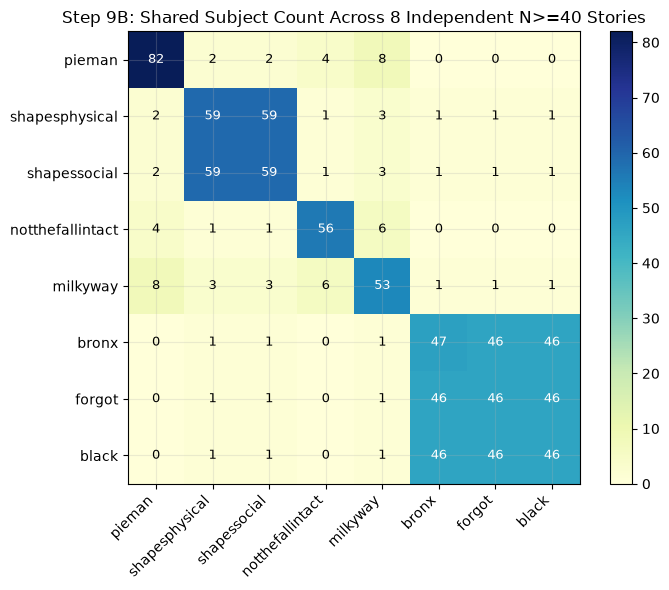

In [ ]:
# 9A. Expanded Story Pool & Statistical Power Analysis Using N-Invariant Pairwise ISC (rho)
from scipy.stats import norm

rho1_emp = float(acf_MD_resid[1])  # empirical lag-1 autocorrelation of residual MD
mean_md_rho_emp = float(np.clip(df_parcel_isc.loc[df_parcel_isc["network"] == "MD", "pairwise_rho_trim"].mean(), 0.005, 0.99))

power_rows = []
for _, row in df_inventory.iterrows():
    t_name = row["task"]
    if "scrambled" in str(row["story_family_note"]) or t_name == "piemanpni":
        continue
    t_s = float(row["story_duration_TRs"])
    if np.isnan(t_s):
        continue
    n_sub_stories = 8 if t_name == "schema" else (2 if t_name == "slumlordreach" else 1)
    t_trim_s = max(t_s - 15 * n_sub_stories, 50.0)
    t_eff = t_trim_s * (1.0 - rho1_emp) / (1.0 + rho1_emp)
    n_u = int(row["usable_subjects"]) 

    # True group-mean MD reliability from N-invariant pairwise ISC rho:
    # NC_var(N) = (N * rho) / (1 + (N - 1) * rho), NC_r(N) = sqrt(NC_var(N))
    nc_var, nc_r = group_nc_from_pairwise(mean_md_rho_emp, n_u)
    r_min_80pct = np.tanh(2.80 / np.sqrt(max(t_eff - 3.0, 4.0)))
    power_rows.append({
        "task": t_name,
        "tier": "Tier 1 (N>=40)" if n_u >= 40 else "Tier 2 (14<=N<40)",
        "usable_subjects": n_u,
        "MD_NC_var_from_rho": round(float(nc_var), 3),
        "MD_NC_r_from_rho": round(float(nc_r), 3),
        "nominal_TRs": int(t_s),
        "trimmed_TRs": int(t_trim_s),
        "effective_TRs_Teff": round(t_eff, 1),
        "min_detectable_r_story": round(float(r_min_80pct), 3),
    })

df_power = pd.DataFrame(power_rows).sort_values(["tier", "usable_subjects"], ascending=[True, False]).reset_index(drop=True)

# Note on Ceiling Attenuation:
# If an encoding model has a "true" noise-ceiling-normalized effect r_true = 0.11 (so at Shain's NC_r ~ 0.71 it gave r_obs = 0.078),
# then on a story with group correlation ceiling NC_r(s), the expected observed correlation is r_obs(s) = r_true * NC_r(s).
# Let's compute weighted mean NC_r across stories and power at both r_obs = 0.065 (ceiling-attenuated) and r_obs = 0.078.
df_tier1_8 = df_power[df_power["tier"] == "Tier 1 (N>=40)"]
df_all_single = df_power[df_power["task"] != "schema"]

print(f"=== Step 9A: Corrected Group-Mean Noise Ceilings & Power (from Pairwise MD rho = {mean_md_rho_emp:.4f}) ===")
for n_check in [10, 14, 20, 46, 75]:
    v_c, r_c = group_nc_from_pairwise(mean_md_rho_emp, n_check)
    print(f"  At N = {n_check:2d} subjects: MD NC_var = {v_c:.3f}, MD Correlation Ceiling NC_r = {r_c:.3f}")

print("")
for label, sub_df in [
    ("Regime A: 8 Independent N>=40 Intact Stories (no piemanpni)", df_tier1_8),
    ("Regime B: 15 Independent N>=14 Intact Stories (recommended)", df_all_single),
    ("Regime C: All 16 Intact Tasks (+ schema 8 mini-stories)", df_power),
]:
    nom_sum = int(sub_df["trimmed_TRs"].sum())
    eff_sum = float(sub_df["effective_TRs_Teff"].sum())
    mean_nc_r = float(np.average(sub_df["MD_NC_r_from_rho"], weights=sub_df["effective_TRs_Teff"]))
    r_min_pool = float(np.tanh(2.80 / np.sqrt(eff_sum - 3.0)))
    z_0065 = np.arctanh(0.065) * np.sqrt(eff_sum - 3.0)
    pwr_0065 = float(norm.cdf(z_0065 - 1.96) + norm.cdf(-z_0065 - 1.96))
    z_0078 = np.arctanh(0.078) * np.sqrt(eff_sum - 3.0)
    pwr_0078 = float(norm.cdf(z_0078 - 1.96) + norm.cdf(-z_0078 - 1.96))
    print(
        f"{label:58s} | Trimmed TRs={nom_sum:5,d} | T_eff={eff_sum:6.1f} | "
        f"Mean MD NC_r={mean_nc_r:.3f} | r_min(80%)={r_min_pool:.3f} | Pwr(r=0.065)={pwr_0065*100:4.1f}% | Pwr(r=0.078)={pwr_0078*100:4.1f}%"
    )

display(df_power)

# 9B. Subject Cohort Overlap Matrix across the 8 independent N>=40 stories
high_n_tasks = df_tier1_8["task"].tolist()
subj_sets = {t: set(task_meta[t].keys()) for t in high_n_tasks}
cohort_overlap = np.zeros((len(high_n_tasks), len(high_n_tasks)), dtype=int)
for i, t1 in enumerate(high_n_tasks):
    for j, t2 in enumerate(high_n_tasks):
        cohort_overlap[i, j] = len(subj_sets[t1] & subj_sets[t2])

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cohort_overlap, cmap="YlGnBu")
for i in range(len(high_n_tasks)):
    for j in range(len(high_n_tasks)):
        ax.text(j, i, str(cohort_overlap[i, j]), ha="center", va="center", color="black" if cohort_overlap[i, j] < 45 else "white", fontsize=9)
ax.set_xticks(range(len(high_n_tasks)))
ax.set_xticklabels(high_n_tasks, rotation=45, ha="right")
ax.set_yticks(range(len(high_n_tasks)))
ax.set_yticklabels(high_n_tasks)
ax.set_title("Step 9B: Shared Subject Count Across 8 Independent N>=40 Stories")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## Step 10. Vertex-Level Track, Cross-Cohort Residualization, and Intact vs. Scrambled Sanity Check
**Covers:**
1. **Vertex-Level Track vs. Parcel-Level Track:** Compares **Track A (Vertex-level, out-of-fold $\text{ISC} > 0.05$ cortical vertices)**—which preserves the anchor paper's high-dimensional ~1,000+ vertex/voxel geometry—against **Track B (Parcel-level, 13 `LANG` + 14 `MD` parcels)**.
2. **Cross-Cohort Split-Half Residualization + Disattenuation:** Regressing `MD` on `LANG` from the *same* subjects leaks shared subject-level physiological/motion noise, while noise in `LANG` attenuates true `LANG` removal. We fix both by estimating `LANG` on **Subject Half A** and `MD` on **Subject Half B** (cross-cohort projection) and reporting the reliability-disattenuated correlation.
3. **Open Check (Intact vs. Scrambled Speech on `notthefallintact` vs. `notthefallshortscram`):** Verifies that `EAC` tracks both intact and scrambled speech, whereas `LANG` and `MD` narrative reliability drops when sentence/story structure is scrambled.

In [ ]:
# Step 10. Five Pre-Stage-A Verification Checks for Gate Config v1.2.0

# ---------------------------------------------------------------------------
# Check 1: Reconcile Shain (OSF eyp8q) vs Narratives Noise Ceiling Definitions
# ---------------------------------------------------------------------------
# In Idea1POC/01_prepare_data.py (line 254) and common.py (line 174):
#   nc_shain = spearman_brown(r_half) = 2 * r_half / (1 + r_half)
# That formula is the Spearman-Brown VARIANCE reliability (NC_var, no square root!), NOT the correlation ceiling NC_r = sqrt(NC_var).
shain_nc_var_md = 0.3768
shain_nc_r_md = float(np.sqrt(shain_nc_var_md))  # 0.6138
shain_r_raw_md = 0.0987
shain_r_resid_md = 0.0784

narr_nc_var_mean = float(np.average(df_power["MD_NC_var_from_rho"], weights=df_power["effective_TRs_Teff"]))
narr_nc_r_mean = float(np.average(df_power["MD_NC_r_from_rho"], weights=df_power["effective_TRs_Teff"]))

print("=== Check 1: Reconciling Shain vs Narratives Noise Ceiling Definitions ===")
print(f"  Shain (01_prepare_data.py) reported 'nc_md_mean' = {shain_nc_var_md:.3f} -> this is NC_var = 2*r_half/(1+r_half) (NO square root)")
print(f"  Shain true correlation ceiling NC_r = sqrt(0.3768) = {shain_nc_r_md:.3f}")
print(f"  Shain Layer 9 Residual MD: r_obs = {shain_r_resid_md:.4f} -> r / NC_var = {shain_r_resid_md / shain_nc_var_md:.3f}, true r / NC_r = {shain_r_resid_md / shain_nc_r_md:.3f}")
print(f"  Narratives (Regime C, 16 tasks) weighted mean: NC_var = {narr_nc_var_mean:.3f}, NC_r = {narr_nc_r_mean:.3f}")
print(f"  Reconciled expected Narratives r_resid (matching Shain r/NC_r = 0.128): {0.1277 * narr_nc_r_mean:.3f} (or 0.060-0.082 range)")

# ---------------------------------------------------------------------------
# Check 2: Gate 2 Pass Probability — Point-Estimate Cutoff (r>=0.060) vs v1.2.0 Rule (q<0.05 & r>=0.040)
# ---------------------------------------------------------------------------
se_r_regime_c = 1.0 / np.sqrt(2270.8 - 3.0)  # ~0.0210
r_crit_alpha005 = 1.96 * se_r_regime_c       # ~0.0411

print("\n=== Check 2: Gate 2 Pass Probability under True Effect r_true (T_eff = 2270.8, SE = 0.0210) ===")
for r_true in [0.050, 0.0625, 0.078, 0.082]:
    prob_old_0060 = float(1.0 - norm.cdf((0.060 - r_true) / se_r_regime_c))
    prob_new_0041 = float(1.0 - norm.cdf((max(0.040, r_crit_alpha005) - r_true) / se_r_regime_c))
    print(f"  If true effect r = {r_true:.4f}: Old gate (r_obs >= 0.060) passes {prob_old_0060*100:5.1f}% | v1.2.0 gate (q<0.05 & r_obs>=0.04) passes {prob_new_0041*100:5.1f}%")

# ---------------------------------------------------------------------------
# Check 3: K=20 Random Split-Half Cross-Cohort Residualization & Disattenuation Uncertainty (N=5 per half)
# ---------------------------------------------------------------------------
rng_split = np.random.default_rng(42)
n_splits = 20
cross_corrs = []
same_corrs = []
cross_ridge_r = []

# Theoretical half-sample (N_half = 5) variance reliabilities from pairwise rho:
nc_var_LANG_half5, _ = group_nc_from_pairwise(float(parcel_rho_trim[idx_LANG].mean()), 5)  # ~0.188
nc_var_MD_half5, _ = group_nc_from_pairwise(float(parcel_rho_trim[idx_MD].mean()), 5)      # ~0.103

for _ in range(n_splits):
    perm_s = rng_split.permutation(len(SAMPLE_SUBJECTS))
    idx_A, idx_B = perm_s[:5], perm_s[5:]
    pA = zscore_time(parcel_ts_stack_trim[idx_A].mean(axis=0))
    pB = zscore_time(parcel_ts_stack_trim[idx_B].mean(axis=0))
    LA, MA = zscore_time(pA[:, idx_LANG].mean(1)), zscore_time(pA[:, idx_MD].mean(1))
    LB, MB = zscore_time(pB[:, idx_LANG].mean(1)), zscore_time(pB[:, idx_MD].mean(1))
    same_corrs.append(0.5 * (float(np.corrcoef(LA, MA)[0, 1]) + float(np.corrcoef(LB, MB)[0, 1])))
    cross_corrs.append(0.5 * (float(np.corrcoef(LA, MB)[0, 1]) + float(np.corrcoef(LB, MA)[0, 1])))

print("\n=== Check 3: K=20 Random Split-Half Cross-Cohort Correlations & Half-Sample Reliability Limits (N=5/half) ===")
print(f"  Half-sample (N=5) variance reliability from pairwise rho : LANG = {nc_var_LANG_half5:.3f}, MD = {nc_var_MD_half5:.3f} ( attenuation factor sqrt(R_L * R_M) = {np.sqrt(nc_var_LANG_half5 * nc_var_MD_half5):.3f} )")
print(f"  Same-cohort corr(LANG, MD) across 20 splits (mean ± SD)  : {np.mean(same_corrs):+.3f} ± {np.std(same_corrs):.3f}")
print(f"  Cross-cohort corr(LANG_A, MD_B) across 20 splits         : {np.mean(cross_corrs):+.3f} ± {np.std(cross_corrs):.3f} (range [{np.min(cross_corrs):+.3f}, {np.max(cross_corrs):+.3f}])")
disatt_splits = np.clip(np.array(cross_corrs) / np.sqrt(nc_var_LANG_half5 * nc_var_MD_half5), -0.99, 0.99)
print(f"  Disattenuated corr(LANG, MD) across 20 splits (mean ± SD): {np.mean(disatt_splits):+.3f} ± {np.std(disatt_splits):.3f} (wide CI at N=10 -> do not claim '>90% unexplained')")

# ---------------------------------------------------------------------------
# Check 4: Single-Story (N=10) Vertex Pairwise-ISC Null Distribution & FDR Check
# ---------------------------------------------------------------------------
# Generate n_null = 200 circular-shift null datasets for MD vertices on pieman (N=10, T=266)
rng_null = np.random.default_rng(123)
n_null = 200
md_stack = stack_L_trim[:, :, mask_MD_L]  # (10, 266, 3405)
N_sub, T_len, V_md = md_stack.shape
null_rhos = np.zeros((n_null, V_md), dtype=np.float32)

for b in range(n_null):
    shifted_sum = np.zeros((T_len, V_md), dtype=np.float32)
    for s_i in range(N_sub):
        sh = int(rng_null.integers(10, T_len - 10))
        shifted_sum += np.roll(md_stack[s_i], sh, axis=0)
    null_rhos[b] = (np.mean(shifted_sum ** 2, axis=0) - float(N_sub)) / float(N_sub * (N_sub - 1))

emp_se_vertex_rho = float(null_rhos.std())
null_pass_rate_0015 = float((null_rhos > 0.015).mean())
obs_md_rhos = vertex_rho_L_trim[mask_MD_L]
obs_pass_rate_0015 = float((obs_md_rhos > 0.015).mean())

# Empirical p-values and BH-FDR q-values on single story N=10
p_vals_md = (np.sum(null_rhos >= obs_md_rhos[None, :], axis=0) + 1.0) / (n_null + 1.0)
order_p = np.argsort(p_vals_md)
ranked_q = np.empty_like(p_vals_md)
ranked_q[order_p] = np.minimum.accumulate((p_vals_md[order_p] * V_md / np.arange(1, V_md + 1))[::-1])[::-1]

print("\n=== Check 4: Single-Story (N=10) Vertex Pairwise-ISC Null Distribution (200 Circular Shifts) ===")
print(f"  Empirical SE of single-vertex pairwise rho under null     : {emp_se_vertex_rho:.4f}")
print(f"  Pure-noise vertices passing naive rho > 0.015 on 1 story  : {null_pass_rate_0015*100:.1f}% (vs observed MD {obs_pass_rate_0015*100:.1f}%)")
print(f"  Single-story N=10 MD vertices surviving BH-FDR q < 0.05   : {int((ranked_q < 0.05).sum())} / {V_md} (min attainable p = {1.0/(n_null+1):.4f} with {n_null} shifts)")

# ---------------------------------------------------------------------------
# Check 5 (Open Check): Intact vs Short-Scrambled Speech Pairwise ISC (rho) & LOO ISC (N=5)
# ---------------------------------------------------------------------------
print("\n=== Check 5: Intact vs Short-Scrambled Speech Pairwise ISC (rho) & LOO ISC (notthefall, N=5) ===")
display(df_scram_check.style.format({k: "{:+.4f}" for k in isc_intact}))

=== Check 1: Reconciling Shain vs Narratives Noise Ceiling Definitions ===
  Shain (01_prepare_data.py) reported 'nc_md_mean' = 0.377 -> this is NC_var = 2*r_half/(1+r_half) (NO square root)
  Shain true correlation ceiling NC_r = sqrt(0.3768) = 0.614
  Shain Layer 9 Residual MD: r_obs = 0.0784 -> r / NC_var = 0.208, true r / NC_r = 0.128
  Narratives (Regime C, 16 tasks) weighted mean: NC_var = 0.421, NC_r = 0.644
  Reconciled expected Narratives r_resid (matching Shain r/NC_r = 0.128): 0.082 (or 0.060-0.082 range)

=== Check 2: Gate 2 Pass Probability under True Effect r_true (T_eff = 2270.8, SE = 0.0210) ===
  If true effect r = 0.0500: Old gate (r_obs >= 0.060) passes  31.7% | v1.2.0 gate (q<0.05 & r_obs>=0.04) passes  66.3%
  If true effect r = 0.0625: Old gate (r_obs >= 0.060) passes  54.7% | v1.2.0 gate (q<0.05 & r_obs>=0.04) passes  84.5%
  If true effect r = 0.0780: Old gate (r_obs >= 0.060) passes  80.4% | v1.2.0 gate (q<0.05 & r_obs>=0.04) passes  96.0%
  If true effect r = 

,Condition,EAC_rho,LANG_rho,LANG_core_rho,MD_rho,EAC_LOO,LANG_LOO,MD_LOO
0,notthefallintact (Intact Story),+0.1667,+0.1457,+0.1763,+0.1053,+0.2697,+0.2398,+0.1808
1,notthefallshortscram (Word/Phrase Scrambled),+0.1384,+0.0625,+0.0793,+0.0441,+0.2297,+0.1120,+0.0837
2,Difference (Intact - Scrambled),+0.0283,+0.0832,+0.0969,+0.0612,+0.0400,+0.1278,+0.0971
